# TLM-M Explainability -- PLE / Per-Hunk Confidence / Copy vs. Generate

Detailed diagnostics kept out of `score_eval.ipynb` -- too fine-grained to walk through cold in a defense. Reuses a cached full greedy-decode eval run for the same checkpoint (same `EVAL_CACHE_DIR`) if one is present, instead of redecoding.

## Clean run -- what to change

This notebook **does not decode from scratch by default.** The "Full Eval Run"
section reuses the full greedy-decode eval cached by `score_eval.ipynb` for the same checkpoint
(`<CKPT_DIR>/thesis_eval_outputs/eval_cache/*.pkl`). The PLE-ablation section runs
a *second* full pass into a separate cache
(`<CKPT_DIR>/explainability_outputs/eval_cache_ple_ablated/`). A committed cache
reproduces the summary with no GPU work. To reproduce *from scratch*:

1. **Environment.** Linux + GPU (Colab / WSL). No `fork` multiprocessing here, but
   the main and ablation passes are both full GPU decodes over the eval set.
2. **Checkpoint identity.** `MODEL_VARIANT` / `RUN_NAME` / `CKPT_NAME` in the Setup
   cell (three lines). Must name a checkpoint that exists under
   `data/checkpoints/<RUN_NAME>/`.
3. **Prime the shared cache.** Either run `score_eval.ipynb` for this checkpoint first, or let this notebook's Full Eval Run cell
   do its own pass -- it writes the same cache.
4. **Force recompute.** Delete both caches:
   `rm -rf <CKPT_DIR>/thesis_eval_outputs/eval_cache/ <CKPT_DIR>/explainability_outputs/eval_cache_ple_ablated/`
5. **Paths.** Colab original: `DRIVE_ROOT`. Local copy: `_localenv.py` (`TLM_DATA`
   env var); no edit needed.


## 1 -- Setup

In [8]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, os, re, json, math, time, random, pickle
from pathlib import Path
from collections import defaultdict, Counter

DRIVE_ROOT = Path('/content/drive/MyDrive/TLM_V03')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first"
sys.path.insert(0, str(DRIVE_ROOT))

from src.model_config import ModelConfig, count_parameters
from src.model_variants import TLM_S
from src.tokenizer import TLM_Tokenizer
from src.data_set import make_sft_sr, apply_sr, split_lines_by_newline, join_lines
from src.data_loaders import SFTDataset, collate_sft
from src.training import validate
from src.inference import greedy_decode, decode_rename_without_collision

import torch
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}  |  PyTorch: {torch.__version__}")

# -- THE final checkpoint -- fixed on purpose, no variant switching. If the
# thesis's final checkpoint changes, update these three lines; everything
# below is derived from RUN_NAME/CKPT_NAME.
MODEL_VARIANT = "M"
RUN_NAME      = "tlm_m_sft_unbiased_copy"
CKPT_NAME     = "tlm_m_sft_unbiased_copy_epoch_25_val0.1605.pt"

TOKENIZER_PATH = str(DRIVE_ROOT / "src" / "tokenizer" / "tokenizer_tlm_small.json")
EVAL_PATH      = DRIVE_ROOT / "data" / "finetune_data" / "sft_val_domain.jsonl"
SFT_CKPT_DIR   = DRIVE_ROOT / "data" / "checkpoints" / RUN_NAME
CKPT_PATH      = SFT_CKPT_DIR / CKPT_NAME

# Cache dir for the full greedy-decode eval. If score_eval.ipynb (or an
# earlier run of this notebook) already decoded this checkpoint into the same
# dir, the run below reuses it instead of redecoding.
THESIS_OUTPUT_DIR = SFT_CKPT_DIR / "thesis_eval_outputs"
EVAL_CACHE_DIR    = THESIS_OUTPUT_DIR / "eval_cache"
# This notebook's own output dir -- kept separate from the shared eval cache
# above so figures never overwrite each other.
OUTPUT_DIR   = SFT_CKPT_DIR / "explainability_outputs"
FIGURES_DIR  = OUTPUT_DIR / "figures"
EVAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"RUN_NAME={RUN_NAME!r}  CKPT_NAME={CKPT_NAME!r}")
print(f"  eval data : {'OK' if EVAL_PATH.exists() else 'MISSING'}  {EVAL_PATH}")
print(f"  checkpoint: {'OK' if CKPT_PATH.exists() else 'MISSING'}  {CKPT_PATH}")
print(f"  outputs -> {OUTPUT_DIR}")

Mounted at /content/drive
Device: cuda  |  PyTorch: 2.11.0+cu128
RUN_NAME='tlm_m_sft_unbiased_copy'  CKPT_NAME='tlm_m_sft_unbiased_copy_epoch_25_val0.1605.pt'
  eval data : OK  /content/drive/MyDrive/TLM_V03/data/finetune_data/sft_val_domain.jsonl
  checkpoint: OK  /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/tlm_m_sft_unbiased_copy_epoch_25_val0.1605.pt
  outputs -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/explainability_outputs


## 2 -- Load Checkpoint

In [9]:
config = ModelConfig(d_model=256, d_ff=1024, tier_name="TLM_M", target_param_count=9_500_000)
tlm_s  = TLM_S(config)
PAD_ID = config.special_token_ids["pad"]

state = torch.load(CKPT_PATH, map_location=device)
tlm_s.load_state_dict(state["model"])
tlm_s.to(device).eval()

print(f"epoch      : {state['epoch']}")
if 'val_reward' in state:
    print(f"val_reward : {state['val_reward']:.4f}")
    for t, s in sorted(state.get('val_per_task', {}).items()):
        print(f"  {t:20s} {s:.4f}")
print(f"Model params: {count_parameters(tlm_s)/1e6:.3f}M")

[tlm_s.py] Initialized TLM_S model variant with 9927937 parameters
epoch      : 25
Model params: 9.928M


## 3 -- Tokenizer + Eval Data

In [10]:
tokenizer = TLM_Tokenizer(vocab_size=config.vocab_size)
tokenizer.load(TOKENIZER_PATH)
print(f"vocab size: {tokenizer.tokenizer.get_vocab_size()}")

by_type = defaultdict(list)
with open(EVAL_PATH, encoding="utf-8") as f:
    for line in f:
        d = json.loads(line)
        by_type[d["type"]].append(d)

print("same-domain held-out eval records per type (EVAL_PATH = sft_val_domain.jsonl, train_domains):")
for t, recs in by_type.items():
    print(f"  {t:20s}: {len(recs)}")
print(f"  total              : {sum(len(v) for v in by_type.values())}")


vocab size: 10000
same-domain held-out eval records per type (EVAL_PATH = sft_val_domain.jsonl, train_domains):
  remove_dead_code    : 750
  rename              : 750
  simplify            : 750
  extract_method      : 750
  deduplicate         : 750
  total              : 3750


## 4 -- Scorers & Task Config

In [ ]:
import sys as _sys
if str(DRIVE_ROOT) not in _sys.path:
    _sys.path.insert(0, str(DRIVE_ROOT))

from src.eval.scorers import (
    score_rename,
    score_extract_method,
    score_simplify,
    score_deduplicate,
    score_text_similarity,
    score_remove_dead_code,
    find_pred_collisions,
    TASK_SCORERS,
)

print("Scorers imported from src/eval/scorers.py (canonical) -- "
      "no inline copy to drift out of sync.")
print("TASK_SCORERS:", {k: v.__name__ for k, v in TASK_SCORERS.items()})


In [12]:
TASK_ORDER = ["rename", "simplify", "deduplicate", "remove_dead_code", "extract_method"]

# applied_ok's per-sample cutoff (is_ok = score >= threshold, used in run_full_eval
# below and the OK/WRONG qualitative sample picker). rename/remove_dead_code's scores
# are recall/consistency/precision products over discrete sites/lines -- many
# different genuinely-correct outputs land exactly at 1.0, so >=0.999 is a meaningful
# "fully correct" bar there. simplify/deduplicate/extract_method's scores are built
# from SequenceMatcher ratios and continuous AST-based proxies (node-count ratio,
# free-name Jaccard) that essentially never land at exact 1.0 unless pred is
# byte-identical to gold -- at >=0.999 applied_ok would silently collapse back into
# "did it reproduce gold's exact text", the single-canonical-answer strictness the
# score redesign was meant to move away from (confirmed empirically: even a verbatim
# gold==pred input only hits >=0.999 ~82-89% of the time for extract_method/
# deduplicate's structural matcher). 0.85 keeps applied_ok informative as a stricter
# secondary signal instead of a near-exact-match one; mean_score stays primary.
OK_SCORE_THRESHOLD = {
    "rename": 0.999,
    "remove_dead_code": 0.999,
    "simplify": 0.85,
    "deduplicate": 0.85,
    "extract_method": 0.85,
}

def _bucket_label_discrete(v, cap):
    if v is None:
        return "n/a"
    return str(v) if v < cap else f"{cap}+"


def _bucket_label_quantile(v, all_vals, n_buckets=3, labels=("short", "medium", "long")):
    if v is None or not all_vals:
        return "n/a"
    sorted_vals = sorted(all_vals)
    edges = [sorted_vals[int(len(sorted_vals) * i / n_buckets)] for i in range(1, n_buckets)]
    idx = sum(1 for e in edges if v > e)
    return labels[min(idx, len(labels) - 1)]


COMPLEXITY_BUCKETS = {
    "rename":           (lambda v, allv: _bucket_label_discrete(v, 4), ["1", "2", "3", "4+", "n/a"]),
    "remove_dead_code": (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "simplify":         (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "deduplicate":      (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "extract_method":   (lambda v, allv: _bucket_label_quantile(v, allv), ["short", "medium", "long", "n/a"]),
}


def _gold_complexities(by_type_dict, ttype):
    """Complexity per record, computed off gold data only (pred=gold trick),
    no model/GPU involved."""
    out = []
    for d in by_type_dict.get(ttype, []):
        before_text = tokenizer.decode(tokenizer.encode(d["before"]))
        gold_text = tokenizer.decode(tokenizer.encode(d["after"]))
        res = TASK_SCORERS[ttype](before_text, gold_text, gold_text)
        out.append(res.get("complexity"))
    return out


print(f"{'task':20s}  {'n':>5}  {'mean':>7}  {'median':>7}")
print("-" * 48)
for ttype in TASK_ORDER:
    vals = [c for c in _gold_complexities(by_type, ttype) if c is not None]
    if vals:
        sv = sorted(vals)
        mean_v = sum(vals) / len(vals)
        median_v = sv[len(sv) // 2]
        print(f"{ttype:20s}  {len(vals):5d}  {mean_v:7.2f}  {median_v:7.2f}")


task                      n     mean   median
------------------------------------------------


<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'


rename                  742    10.64    10.00
simplify                750     1.19     1.00


<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:11: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:11: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning:

deduplicate             718     4.54     4.00
remove_dead_code        750     1.94     2.00
extract_method          750     5.95     6.00


## 5 -- Full Eval Run (reused from a cached run if present)

In [13]:
_NL = config.special_token_ids["newline"]
_BOS = config.special_token_ids["bos"]
_EOS = config.special_token_ids["eos"]
_SEARCH_ID = config.special_token_ids["search"]
_REPLACE_ID = config.special_token_ids["replace"]


def show_sr_pairs(dec_ids):
    body = [t for t in dec_ids if t not in (_BOS, _EOS)]
    i = 0
    pairs = []
    while i < len(body):
        if body[i] != _SEARCH_ID: i += 1; continue
        i += 1; s_start = i
        while i < len(body) and body[i] != _REPLACE_ID: i += 1
        search_ids = body[s_start:i]; i += 1
        r_start = i
        while i < len(body) and body[i] != _SEARCH_ID: i += 1
        replace_ids = body[r_start:i]
        pairs.append((tuple(search_ids), tuple(replace_ids)))
    return pairs


def hunk_confidence(dec_ids, confs):
    """(hunk_index, role, conf) per content token -- excludes <bos>/<eos>/<search>/<replace>
    structural markers, same convention training.py's p_gen penalty uses."""
    out = []
    hunk_idx = -1
    role = None
    for i in range(1, len(dec_ids)):
        tok = dec_ids[i]
        conf = confs[i - 1] if i - 1 < len(confs) else None
        if tok == _SEARCH_ID:
            hunk_idx += 1; role = "search"; continue
        if tok == _REPLACE_ID:
            role = "replace"; continue
        if tok in (_BOS, _EOS) or conf is None or role is None:
            continue
        out.append((hunk_idx, role, conf))
    return out

In [14]:
PROGRESS_EVERY = 10


def _pick_representative(sample_records, k=5):
    """Keeps up to k samples spanning the score range (roughly half lowest,
    half highest) so the qualitative-examples section reliably has both a
    correct and an incorrect example per task, not just whatever decoded first."""
    if len(sample_records) <= k:
        return sample_records
    ranked = sorted(sample_records, key=lambda r: r["score"])
    n_low = k // 2
    n_high = k - n_low
    picked = ranked[:n_low] + ranked[-n_high:]
    seen, out = set(), []
    for r in picked:
        if id(r) not in seen:
            seen.add(id(r)); out.append(r)
    return out


def _ttype_cache_path(cache_dir, ttype):
    return cache_dir / f"{ttype}_full.pkl"


def run_full_eval(by_type_dict, model, progress_every=PROGRESS_EVERY, cache_dir=EVAL_CACHE_DIR, resume=True):
    """Full greedy-decode eval over every record in by_type_dict. Caches each
    task type to disk the moment it finishes -- a dropped Colab session only
    costs whatever task type was in-flight, and re-running this cell picks up
    from the cache instead of redecoding from scratch."""
    results = {}
    all_records = []
    t0 = time.perf_counter()
    n_done = 0
    n_total = sum(len(recs) for recs in by_type_dict.values())

    for ttype, recs in by_type_dict.items():
        cache_path = _ttype_cache_path(cache_dir, ttype)
        if resume and cache_path.exists():
            with open(cache_path, "rb") as f:
                cached = pickle.load(f)
            results[ttype] = cached["results_entry"]
            all_records.extend(cached["representative_records"])
            n_done += len(recs)
            r = results[ttype]
            print(f"--- [{ttype}] loaded from cache: {r['ok']}/{r['total']} ok, "
                  f"mean_score={sum(r['scores'])/max(len(r['scores']),1):.3f} ---", flush=True)
            continue

        print(f"\n--- [{ttype}] starting, {len(recs)} samples ---", flush=True)
        ok = trunc = parse_fail = total = 0
        conf_ok, conf_wrong = [], []
        min_conf_ok, min_conf_wrong, p05_conf_ok, p05_conf_wrong = [], [], [], []
        scores, complexities, confs, min_confs, p05_confs = [], [], [], [], []
        hunk_conf_records = []
        sample_records = []
        sample_idx = 0
        for i, d in enumerate(recs):
            res = make_sft_sr(d, tokenizer, config)
            if res is None:
                continue
            enc_ids, _, task_id = res
            before_ids = tokenizer.encode(d["before"])
            after_ids  = tokenizer.encode(d["after"])
            gold_after = join_lines(split_lines_by_newline(after_ids, _NL), _NL)

            if ttype == "rename":
                out = decode_rename_without_collision(model, enc_ids, task_id, device, before_ids,
                                                      tokenizer, config, max_retries=2, collect_conf=True)
            else:
                out = greedy_decode(model, enc_ids, task_id, device, collect_conf=True)
            pred_dec = out["tokens"]
            mean_conf = out["mean_conf"]
            step_confs = out["confs"]
            pred_after = apply_sr(before_ids, pred_dec, config)

            hunk_confs_this = hunk_confidence(pred_dec, step_confs)
            content_confs = [c for (_, _, c) in hunk_confs_this]
            min_conf = min(content_confs) if content_confs else mean_conf
            p05_conf = float(np.percentile(content_confs, 5)) if content_confs else mean_conf

            total += 1
            if pred_dec[-1] != _EOS:
                trunc += 1

            before_text = tokenizer.decode(before_ids)
            pred_text = tokenizer.decode(pred_after) if pred_after is not None else None
            gold_text = tokenizer.decode(gold_after)
            score_result = TASK_SCORERS[ttype](before_text, pred_text, gold_text)
            sample_score = score_result["score"]
            is_ok = sample_score >= OK_SCORE_THRESHOLD.get(ttype, 0.999)
            if pred_after is None:
                parse_fail += 1

            scores.append(sample_score)
            complexities.append(score_result.get("complexity"))
            confs.append(mean_conf); min_confs.append(min_conf); p05_confs.append(p05_conf)
            for h_idx, role, c in hunk_confs_this:
                hunk_conf_records.append({"sample_idx": sample_idx, "hunk_idx": h_idx, "role": role, "conf": c})
            sample_idx += 1
            if is_ok:
                ok += 1
                conf_ok.append(mean_conf); min_conf_ok.append(min_conf); p05_conf_ok.append(p05_conf)
            else:
                conf_wrong.append(mean_conf); min_conf_wrong.append(min_conf); p05_conf_wrong.append(p05_conf)
            sample_records.append({"d": d, "enc_ids": enc_ids, "task_id": task_id,
                                   "pred_dec": pred_dec, "pred_after": pred_after,
                                   "gold_after": gold_after, "before_ids": before_ids,
                                   "mean_conf": mean_conf, "is_ok": is_ok,
                                   "min_conf": min_conf, "p05_conf": p05_conf,
                                   "score": sample_score, "complexity": score_result.get("complexity")})
            n_done += 1
            if (i + 1) % progress_every == 0 or (i + 1) == len(recs):
                elapsed = time.perf_counter() - t0
                eta = (n_total - n_done) / max(n_done / max(elapsed, 1e-9), 1e-9)
                print(f"  [{ttype}] {i+1}/{len(recs)}  ok so far: {ok}  "
                      f"| overall {n_done}/{n_total}  elapsed {elapsed:.0f}s  ETA {eta:.0f}s", flush=True)

        results[ttype] = {"ok": ok, "total": total, "trunc": trunc, "parse_fail": parse_fail,
                          "conf_ok": conf_ok, "conf_wrong": conf_wrong,
                          "min_conf_ok": min_conf_ok, "min_conf_wrong": min_conf_wrong,
                          "p05_conf_ok": p05_conf_ok, "p05_conf_wrong": p05_conf_wrong,
                          "scores": scores, "complexities": complexities, "confs": confs,
                          "min_confs": min_confs, "p05_confs": p05_confs,
                          "hunk_conf_records": hunk_conf_records}
        representative_records = _pick_representative(sample_records, k=5)
        all_records.extend(representative_records)
        with open(cache_path, "wb") as f:
            pickle.dump({"results_entry": results[ttype], "representative_records": representative_records}, f)
        mean_score = sum(scores) / max(len(scores), 1)
        print(f"{ttype:20s}: {ok:3d}/{total:<3d} ({ok/max(total,1)*100:5.1f}%)  mean_score={mean_score:.3f}  "
              f"trunc={trunc}  parse_fail={parse_fail}  [cached -> {cache_path.name}]")

    elapsed = time.perf_counter() - t0
    total_ok  = sum(v["ok"]    for v in results.values())
    total_tot = sum(v["total"] for v in results.values())
    print(f"\n{'OVERALL':20s}: {total_ok:3d}/{total_tot:<3d} ({total_ok/max(total_tot,1)*100:5.1f}%)  "
          f"elapsed {elapsed:.0f}s")
    return results, all_records, total_ok, total_tot


results, all_records, total_ok, total_tot = run_full_eval(by_type, tlm_s)


--- [remove_dead_code] starting, 750 samples ---
  [remove_dead_code] 10/750  ok so far: 8  | overall 10/3750  elapsed 3s  ETA 1008s
  [remove_dead_code] 20/750  ok so far: 15  | overall 20/3750  elapsed 4s  ETA 828s
  [remove_dead_code] 30/750  ok so far: 25  | overall 30/3750  elapsed 6s  ETA 753s
  [remove_dead_code] 40/750  ok so far: 33  | overall 40/3750  elapsed 8s  ETA 731s
  [remove_dead_code] 50/750  ok so far: 43  | overall 50/3750  elapsed 10s  ETA 725s
  [remove_dead_code] 60/750  ok so far: 51  | overall 60/3750  elapsed 12s  ETA 716s
  [remove_dead_code] 70/750  ok so far: 59  | overall 70/3750  elapsed 13s  ETA 707s
  [remove_dead_code] 80/750  ok so far: 66  | overall 80/3750  elapsed 15s  ETA 708s
  [remove_dead_code] 90/750  ok so far: 74  | overall 90/3750  elapsed 17s  ETA 693s
  [remove_dead_code] 100/750  ok so far: 81  | overall 100/3750  elapsed 19s  ETA 694s
  [remove_dead_code] 110/750  ok so far: 89  | overall 110/3750  elapsed 21s  ETA 685s
  [remove_dead_

<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'


  [rename] 630/750  ok so far: 262  | overall 1380/3750  elapsed 1218s  ETA 2091s


<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'


  [rename] 640/750  ok so far: 266  | overall 1390/3750  elapsed 1236s  ETA 2099s
  [rename] 650/750  ok so far: 272  | overall 1400/3750  elapsed 1250s  ETA 2098s


...

  [deduplicate] 210/750  ok so far: 49  | overall 3209/3750  elapsed 3104s  ETA 523s
  [deduplicate] 220/750  ok so far: 52  | overall 3218/3750  elapsed 3122s  ETA 516s
  [deduplicate] 230/750  ok so far: 53  | overall 3228/3750  elapsed 3139s  ETA 508s
  [deduplicate] 240/750  ok so far: 54  | overall 3238/3750  elapsed 3155s  ETA 499s
  [deduplicate] 250/750  ok so far: 58  | overall 3248/3750  elapsed 3170s  ETA 490s
  [deduplicate] 260/750  ok so far: 61  | overall 3258/3750  elapsed 3186s  ETA 481s
  [deduplicate] 270/750  ok so far: 63  | overall 3268/3750  elapsed 3202s  ETA 472s


<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: 

  [deduplicate] 280/750  ok so far: 65  | overall 3278/3750  elapsed 3220s  ETA 464s
  [deduplicate] 290/750  ok so far: 68  | overall 3288/3750  elapsed 3236s  ETA 455s
  [deduplicate] 300/750  ok so far: 69  | overall 3298/3750  elapsed 3253s  ETA 446s
  [deduplicate] 310/750  ok so far: 74  | overall 3308/3750  elapsed 3274s  ETA 437s
  [deduplicate] 320/750  ok so far: 77  | overall 3318/3750  elapsed 3290s  ETA 428s
  [deduplicate] 330/750  ok so far: 77  | overall 3328/3750  elapsed 3305s  ETA 419s
  [deduplicate] 340/750  ok so far: 79  | overall 3338/3750  elapsed 3323s  ETA 410s
  [deduplicate] 350/750  ok so far: 81  | overall 3348/3750  elapsed 3340s  ETA 401s
  [deduplicate] 360/750  ok so far: 81  | overall 3358/3750  elapsed 3356s  ETA 392s
  [deduplicate] 370/750  ok so far: 85  | overall 3368/3750  elapsed 3370s  ETA 382s
  [deduplicate] 380/750  ok so far: 89  | overall 3377/3750  elapsed 3387s  ETA 374s
  [deduplicate] 390/750  ok so far: 91  | overall 3387/3750  elap

<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:5: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:5: SyntaxWarning: invalid escape sequence '\D'
<unknown>:5: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:5: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:5: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: 

  [deduplicate] 730/750  ok so far: 154  | overall 3727/3750  elapsed 3983s  ETA 25s
  [deduplicate] 740/750  ok so far: 157  | overall 3737/3750  elapsed 4001s  ETA 14s
  [deduplicate] 750/750  ok so far: 161  | overall 3747/3750  elapsed 4019s  ETA 3s
deduplicate         : 161/747 ( 21.6%)  mean_score=0.442  trunc=13  parse_fail=43  [cached -> deduplicate_full.pkl]

OVERALL             : 1494/3747 ( 39.9%)  elapsed 4020s


In [15]:
task_mean_scores = {t: sum(results[t]["scores"]) / max(len(results[t]["scores"]), 1)
                    for t in TASK_ORDER if t in results}
overall_score = sum(task_mean_scores.values()) / max(len(task_mean_scores), 1)
print(f"overall_score (for the PLE ablation delta below): {overall_score:.3f}")

overall_score (for the PLE ablation delta below): 0.582


## 6 -- Per-Layer Task Embeddings (PLE) -- Descriptive

 layer          pretrain            rename          simplify       deduplicate  remove_dead_code    extract_method
     0             0.539             0.292             0.204             0.171             0.221             0.185
     1             1.054             0.309             0.304             0.214             0.444             0.259
     2             0.720             0.269             0.305             0.207             0.448             0.257
     3             0.670             0.247             0.306             0.181             0.489             0.232


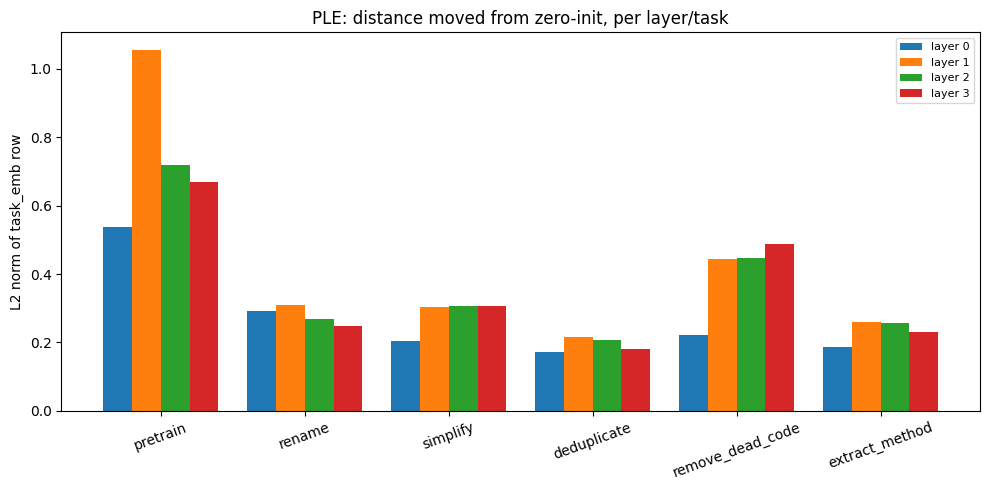

In [16]:
_TASK_ID_NAMES = {0: "pretrain", 1: "rename", 2: "simplify", 3: "deduplicate",
                   4: "remove_dead_code", 5: "extract_method"}
n_layers = len(tlm_s.encoder.blocks)
n_tasks = config.n_task_types

ple_norms = np.zeros((n_layers, n_tasks))
for li, blk in enumerate(tlm_s.encoder.blocks):
    w = blk.task_emb.weight.detach().cpu().numpy()
    ple_norms[li] = np.linalg.norm(w, axis=1)

print(f"{'layer':>6}  " + "  ".join(f"{_TASK_ID_NAMES.get(i, i):>16}" for i in range(n_tasks)))
for li in range(n_layers):
    print(f"{li:>6}  " + "  ".join(f"{ple_norms[li, i]:>16.3f}" for i in range(n_tasks)))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(n_tasks)
w_bar = 0.8 / n_layers
for li in range(n_layers):
    ax.bar(x + li * w_bar, ple_norms[li], width=w_bar, label=f"layer {li}")
ax.set_xticks(x + w_bar * (n_layers - 1) / 2)
ax.set_xticklabels([_TASK_ID_NAMES.get(i, str(i)) for i in range(n_tasks)], rotation=20)
ax.set_ylabel("L2 norm of task_emb row")
ax.set_title("PLE: distance moved from zero-init, per layer/task")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ple_norms.png", dpi=150, bbox_inches="tight")
plt.show()

## 7 -- PLE Ablation: How Much Does It Actually Contribute?

Re-runs the full eval with every layer's task embedding zeroed out (separate cache, does not touch the main run). Real GPU cost -- a second full pass over the eval set.


--- [remove_dead_code] starting, 750 samples ---
  [remove_dead_code] 10/750  ok so far: 7  | overall 10/3750  elapsed 2s  ETA 872s
  [remove_dead_code] 20/750  ok so far: 13  | overall 20/3750  elapsed 4s  ETA 798s
  [remove_dead_code] 30/750  ok so far: 22  | overall 30/3750  elapsed 6s  ETA 773s
  [remove_dead_code] 40/750  ok so far: 30  | overall 40/3750  elapsed 9s  ETA 798s
  [remove_dead_code] 50/750  ok so far: 38  | overall 50/3750  elapsed 10s  ETA 776s
  [remove_dead_code] 60/750  ok so far: 45  | overall 60/3750  elapsed 12s  ETA 746s
  [remove_dead_code] 70/750  ok so far: 52  | overall 70/3750  elapsed 14s  ETA 751s
  [remove_dead_code] 80/750  ok so far: 59  | overall 80/3750  elapsed 17s  ETA 762s
  [remove_dead_code] 90/750  ok so far: 65  | overall 90/3750  elapsed 18s  ETA 752s
  [remove_dead_code] 100/750  ok so far: 73  | overall 100/3750  elapsed 21s  ETA 776s
  [remove_dead_code] 110/750  ok so far: 78  | overall 110/3750  elapsed 24s  ETA 779s
  [remove_dead_c

<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'
<unknown>:8: SyntaxWarning: invalid escape sequence '\D'


  [rename] 640/750  ok so far: 0  | overall 1390/3750  elapsed 380s  ETA 646s
  [rename] 650/750  ok so far: 0  | overall 1400/3750  elapsed 382s  ETA 642s


<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'
<unknown>:6: SyntaxWarning: invalid escape sequence '\s'


  [rename] 660/750  ok so far: 0  | overall 1410/3750  elapsed 385s  ETA 639s
  [rename] 670/750  ok so far: 0  | overall 1420/3750  elapsed 389s  ETA 638s
  [rename] 680/750  ok so far: 0  | overall 1430/3750  elapsed 392s  ETA 636s
  [rename] 690/750  ok so far: 0  | overall 1440/3750  elapsed 396s  ETA 635s
  [rename] 700/750  ok so far: 0  | overall 1450/3750  elapsed 398s  ETA 632s
  [rename] 710/750  ok so far: 0  | overall 1460/3750  elapsed 402s  ETA 631s
  [rename] 720/750  ok so far: 0  | overall 1470/3750  elapsed 404s  ETA 627s
  [rename] 730/750  ok so far: 0  | overall 1480/3750  elapsed 407s  ETA 624s
  [rename] 740/750  ok so far: 0  | overall 1490/3750  elapsed 410s  ETA 623s
  [rename] 750/750  ok so far: 0  | overall 1500/3750  elapsed 415s  ETA 622s
rename              :   0/750 (  0.0%)  mean_score=0.000  trunc=0  parse_fail=43  [cached -> rename_full.pkl]

--- [simplify] starting, 750 samples ---
  [simplify] 10/750  ok so far: 3  | overall 1510/3750  elapsed 422s

...

  [deduplicate] 210/750  ok so far: 1  | overall 3209/3750  elapsed 1475s  ETA 249s
  [deduplicate] 220/750  ok so far: 1  | overall 3218/3750  elapsed 1484s  ETA 245s
  [deduplicate] 230/750  ok so far: 1  | overall 3228/3750  elapsed 1490s  ETA 241s
  [deduplicate] 240/750  ok so far: 1  | overall 3238/3750  elapsed 1497s  ETA 237s
  [deduplicate] 250/750  ok so far: 1  | overall 3248/3750  elapsed 1502s  ETA 232s
  [deduplicate] 260/750  ok so far: 1  | overall 3258/3750  elapsed 1508s  ETA 228s
  [deduplicate] 270/750  ok so far: 1  | overall 3268/3750  elapsed 1513s  ETA 223s


<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:10: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'
<unknown>:5: SyntaxWarning: invalid escape sequence '\s'


  [deduplicate] 280/750  ok so far: 1  | overall 3278/3750  elapsed 1520s  ETA 219s
  [deduplicate] 290/750  ok so far: 1  | overall 3288/3750  elapsed 1526s  ETA 214s
  [deduplicate] 300/750  ok so far: 1  | overall 3298/3750  elapsed 1533s  ETA 210s
  [deduplicate] 310/750  ok so far: 1  | overall 3308/3750  elapsed 1541s  ETA 206s
  [deduplicate] 320/750  ok so far: 1  | overall 3318/3750  elapsed 1547s  ETA 201s
  [deduplicate] 330/750  ok so far: 1  | overall 3328/3750  elapsed 1550s  ETA 197s
  [deduplicate] 340/750  ok so far: 1  | overall 3338/3750  elapsed 1555s  ETA 192s
  [deduplicate] 350/750  ok so far: 1  | overall 3348/3750  elapsed 1562s  ETA 188s
  [deduplicate] 360/750  ok so far: 1  | overall 3358/3750  elapsed 1567s  ETA 183s
  [deduplicate] 370/750  ok so far: 1  | overall 3368/3750  elapsed 1571s  ETA 178s
  [deduplicate] 380/750  ok so far: 1  | overall 3377/3750  elapsed 1577s  ETA 174s
  [deduplicate] 390/750  ok so far: 1  | overall 3387/3750  elapsed 1584s  E

<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:11: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:11: SyntaxWarning: invalid escape sequence '\D'
<unknown>:11: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:6: SyntaxWarning: invalid escape sequence '\D'
<unknown>:12: SyntaxWarning: invalid escape sequence '\D'
<unknown>:11: SyntaxWarning: invalid escape sequence '\D'
<unknown>:7: SyntaxWarning: invalid escape sequence '\D'
<unknown>:11: SyntaxWarn

  [deduplicate] 730/750  ok so far: 3  | overall 3727/3750  elapsed 1783s  ETA 11s
  [deduplicate] 740/750  ok so far: 3  | overall 3737/3750  elapsed 1790s  ETA 6s
  [deduplicate] 750/750  ok so far: 3  | overall 3747/3750  elapsed 1796s  ETA 1s
deduplicate         :   3/747 (  0.4%)  mean_score=0.142  trunc=25  parse_fail=245  [cached -> deduplicate_full.pkl]

OVERALL             : 633/3747 ( 16.9%)  elapsed 1796s

task                     normal      PLE=0    delta
----------------------------------------------------
rename                    0.636      0.000   -0.636
simplify                  0.530      0.316   -0.214
deduplicate               0.442      0.142   -0.300
remove_dead_code          0.873      0.781   -0.092
extract_method            0.427      0.028   -0.399
----------------------------------------------------
OVERALL                   0.582      0.253   -0.328


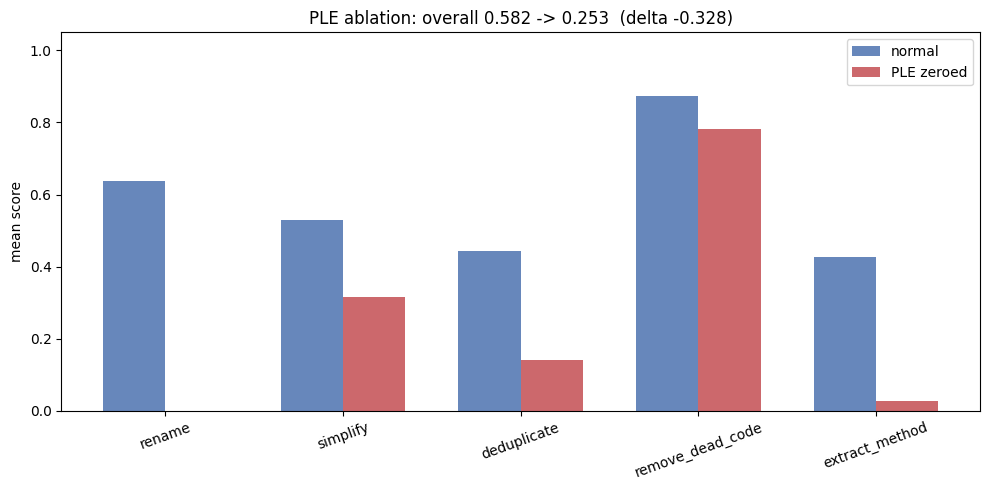

In [17]:
import copy

ABLATED_CACHE_DIR = OUTPUT_DIR / "eval_cache_ple_ablated"
ABLATED_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def zero_out_task_embeddings(model):
    m = copy.deepcopy(model)
    for blk in m.encoder.blocks:
        blk.task_emb.weight.data.zero_()
    m.eval()
    return m


tlm_s_ablated = zero_out_task_embeddings(tlm_s)
results_ablated, all_records_ablated, total_ok_ablated, total_tot_ablated = run_full_eval(
    by_type, tlm_s_ablated, cache_dir=ABLATED_CACHE_DIR)

task_mean_scores_ablated = {}
for t in TASK_ORDER:
    if t not in results_ablated:
        continue
    task_mean_scores_ablated[t] = sum(results_ablated[t]["scores"]) / max(len(results_ablated[t]["scores"]), 1)
overall_score_ablated = sum(task_mean_scores_ablated.values()) / max(len(task_mean_scores_ablated), 1)

print(f"\n{'task':20s} {'normal':>10} {'PLE=0':>10} {'delta':>8}")
print("-" * 52)
ple_ablation_table = []
for t in TASK_ORDER:
    if t not in task_mean_scores or t not in task_mean_scores_ablated:
        continue
    delta = task_mean_scores_ablated[t] - task_mean_scores[t]
    print(f"{t:20s} {task_mean_scores[t]:10.3f} {task_mean_scores_ablated[t]:10.3f} {delta:8.3f}")
    ple_ablation_table.append({"task": t, "normal": task_mean_scores[t],
                                "ple_zeroed": task_mean_scores_ablated[t], "delta": delta})
overall_delta = overall_score_ablated - overall_score
print("-" * 52)
print(f"{'OVERALL':20s} {overall_score:10.3f} {overall_score_ablated:10.3f} {overall_delta:8.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
tasks_plot_ple = [t for t in TASK_ORDER if t in task_mean_scores and t in task_mean_scores_ablated]
x = np.arange(len(tasks_plot_ple)); w = 0.35
ax.bar(x - w/2, [task_mean_scores[t] for t in tasks_plot_ple], width=w, label="normal", color="#4C72B0", alpha=0.85)
ax.bar(x + w/2, [task_mean_scores_ablated[t] for t in tasks_plot_ple], width=w, label="PLE zeroed", color="#C44E52", alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(tasks_plot_ple, rotation=20)
ax.set_ylim(0, 1.05); ax.set_ylabel("mean score")
ax.set_title(f"PLE ablation: overall {overall_score:.3f} -> {overall_score_ablated:.3f}  (delta {overall_delta:+.3f})")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ple_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

## 8 -- Per-Hunk Confidence (working-memory decay check)

task                   hunk   n_hunks   mean_conf   mean_min_conf
------------------------------------------------------------------
rename                    1       750       0.953           0.223
rename                    2       442       0.959           0.415
rename                    3       137       0.957           0.394
rename                   4+        32       0.956           0.420
simplify                  1       750       0.967           0.525
simplify                  2       144       0.959           0.538
simplify                  3        45       0.952           0.624
simplify                 4+         6       0.957           0.697
deduplicate               1       747       0.952           0.391
deduplicate               2       737       0.972           0.571
deduplicate               3       406       0.975           0.585
deduplicate              4+       125       0.979           0.599
remove_dead_code          1       750       0.989           0.870
remove_de

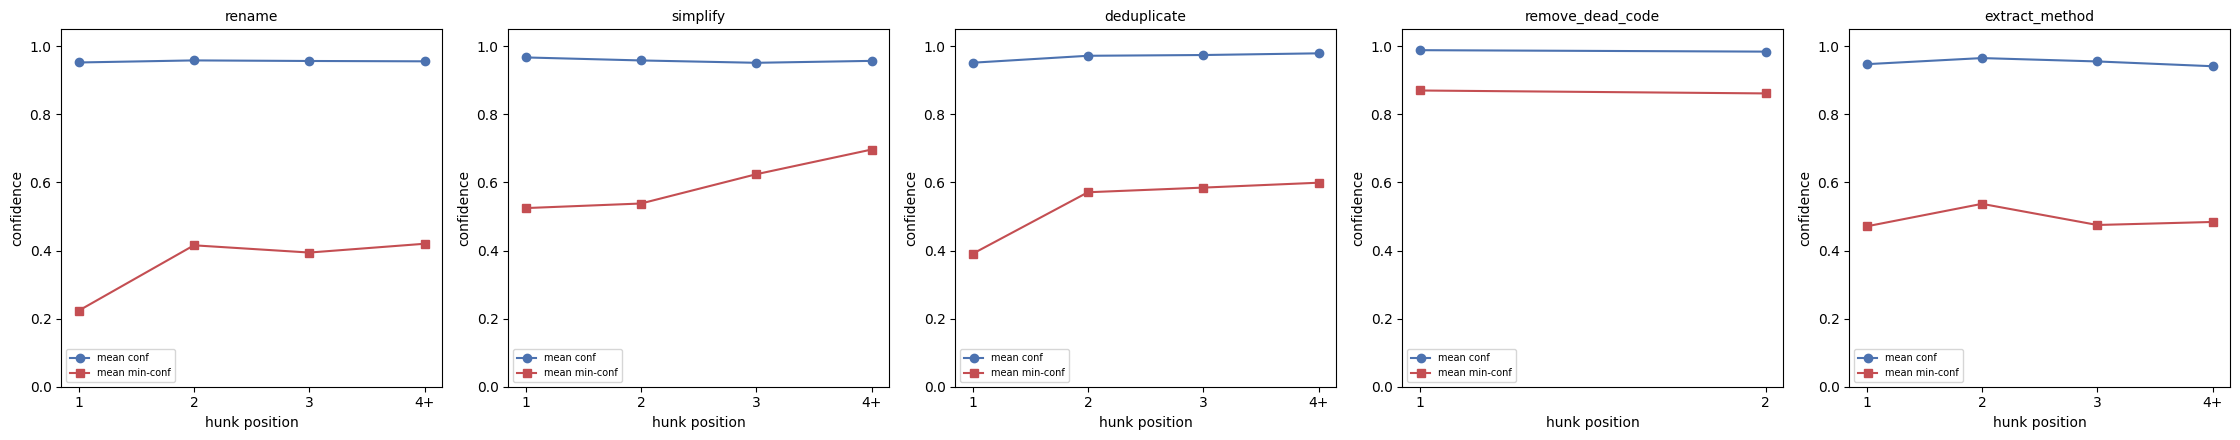

Falling confidence across hunk position would signal working-memory degradation (more capacity likely needed). Flat/rising confidence despite applied_ok dropping means confidently-wrong -- a different failure mode, not memory decay.


In [18]:
HUNK_BUCKET_CAP = 3


def _hunk_bucket(hunk_idx):
    return str(hunk_idx + 1) if hunk_idx < HUNK_BUCKET_CAP else f"{HUNK_BUCKET_CAP + 1}+"


fig, axes = plt.subplots(1, len(TASK_ORDER), figsize=(4.5 * len(TASK_ORDER), 4.5))
if len(TASK_ORDER) == 1:
    axes = [axes]

print(f"{'task':20s} {'hunk':>6}  {'n_hunks':>8}  {'mean_conf':>10}  {'mean_min_conf':>14}")
print("-" * 66)
hunk_confidence_table = []
for ax, ttype in zip(axes, TASK_ORDER):
    recs = results.get(ttype, {}).get("hunk_conf_records", [])
    if not recs:
        continue

    mean_by_bucket = defaultdict(list)
    for r in recs:
        mean_by_bucket[_hunk_bucket(r["hunk_idx"])].append(r["conf"])

    per_hunk_min = defaultdict(lambda: float("inf"))
    for r in recs:
        key = (r["sample_idx"], r["hunk_idx"])
        per_hunk_min[key] = min(per_hunk_min[key], r["conf"])
    min_by_bucket = defaultdict(list)
    for (sidx, hidx), min_conf in per_hunk_min.items():
        min_by_bucket[_hunk_bucket(hidx)].append(min_conf)

    bucket_order = [str(i) for i in range(1, HUNK_BUCKET_CAP + 1)] + [f"{HUNK_BUCKET_CAP + 1}+"]
    labels_present = [l for l in bucket_order if l in mean_by_bucket]
    mean_vals = [sum(mean_by_bucket[l]) / len(mean_by_bucket[l]) for l in labels_present]
    min_vals = [sum(min_by_bucket[l]) / len(min_by_bucket[l]) if l in min_by_bucket else None for l in labels_present]

    for l, mv, mnv in zip(labels_present, mean_vals, min_vals):
        n = len(min_by_bucket.get(l, []))
        print(f"{ttype:20s} {l:>6}  {n:>8}  {mv:>10.3f}  {(mnv if mnv is not None else float('nan')):>14.3f}")
        hunk_confidence_table.append({"task": ttype, "hunk_bucket": l, "n": n, "mean_conf": mv, "mean_min_conf": mnv})

    x = np.arange(len(labels_present))
    ax.plot(x, mean_vals, marker="o", color="#4C72B0", label="mean conf")
    ax.plot(x, [v if v is not None else np.nan for v in min_vals], marker="s", color="#C44E52", label="mean min-conf")
    ax.set_xticks(x); ax.set_xticklabels(labels_present)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("hunk position"); ax.set_ylabel("confidence")
    ax.set_title(ttype, fontsize=10)
    ax.legend(fontsize=7)
print()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "hunk_confidence.png", dpi=150, bbox_inches="tight")
plt.show()

print("Falling confidence across hunk position would signal working-memory degradation "
      "(more capacity likely needed). Flat/rising confidence despite applied_ok dropping "
      "means confidently-wrong -- a different failure mode, not memory decay.")

## 9 -- Copy vs. Generate & Cross-Attention (best + worst sample per task)

In [19]:
def _pick_best_and_worst_per_task(records, task_order):
    """For each task type, finds the highest-scoring ("best") and lowest-scoring
    ("worst") sample among `records` -- the score-diverse pool `_pick_representative`
    already kept per task in the main eval loop (Cell 20/21, up to 5 samples spanning
    the score range). Falls back to the same record for both slots if a task's pool
    only has one record. Returns {f"{ttype}_best": (rec, label), f"{ttype}_worst":
    (rec, label)}, skipping any task with zero records in the pool."""
    by_ttype = defaultdict(list)
    for rec in records:
        by_ttype[rec["d"]["type"]].append(rec)

    targets = {}
    for ttype in task_order:
        recs = by_ttype.get(ttype)
        if not recs:
            continue
        best = max(recs, key=lambda r: r["score"])
        worst = min(recs, key=lambda r: r["score"])
        targets[f"{ttype}_best"] = (best, f"{ttype} BEST (score={best['score']:.3f})")
        targets[f"{ttype}_worst"] = (worst, f"{ttype} WORST (score={worst['score']:.3f})")
    return targets


In [20]:
_explain_targets = _pick_best_and_worst_per_task(all_records, TASK_ORDER)
print(f"Explaining {len(_explain_targets)} samples across {len(TASK_ORDER)} tasks:",
      list(_explain_targets.keys()))

_explain_traces = {}
for key, (rec, label) in _explain_targets.items():
    # rename records in `all_records` were decoded via decode_rename_without_collision
    # in run_full_eval (Cell 20), which can retry with banned_ngrams on a detected
    # name-collision -- a plain greedy_decode() re-decode here would legitimately
    # differ from rec["pred_dec"] whenever that repair path fired, not because
    # decoding is nondeterministic. Match the same decode function per task type
    # so the re-decode assert compares like with like.
    # collect_conf=True (changed from False) -- needed for the copy/generate
    # attribution below (07c): P_final[chosen_token] == confs[step], since the
    # chosen token is always the argmax (probs_t.max() == probs_t[nxt]).
    if rec["d"]["type"] == "rename":
        out = decode_rename_without_collision(tlm_s, rec["enc_ids"], rec["task_id"], device,
                                               rec["before_ids"], tokenizer, config, max_retries=2,
                                               collect_conf=True, collect_pgen=True, collect_attn=True)
    else:
        out = greedy_decode(tlm_s, rec["enc_ids"], rec["task_id"], device,
                             collect_conf=True, collect_pgen=True, collect_attn=True)

    # Re-decode CAN legitimately differ from rec["pred_dec"] even for the same
    # decode function on the same inputs: CopyPointerHead.forward uses
    # scatter_add_ (src/model_components/copy_pointer.py) to build the copy
    # distribution, which is a known GPU floating-point nondeterminism source
    # (summation order not fixed -- see PyTorch's reproducibility notes). Most
    # steps are unaffected (~1e-7 noise), but at a near-tied top-1 step the
    # noise can flip the argmax, and the KV-cached autoregressive continuation
    # diverges from there on -- more likely on low-scoring/borderline samples
    # (e.g. rename_worst) where near-ties are more common. This is NOT a bug
    # in greedy_decode itself (still a pure argmax, no sampling) and forcing
    # torch.use_deterministic_algorithms(True) repo-wide would only fix it
    # going forward, not retroactively match the already-cached run_full_eval
    # tokens above. So: don't hard-crash the whole diagnostic cell on a
    # mismatch -- warn, and fall back to this re-decode's own tokens/score so
    # the pgen/attn/conf trace plotted below (07c) always stays internally
    # consistent with the tokens it was actually collected from.
    if out["tokens"] != rec["pred_dec"]:
        print(f"  [warn] re-decode mismatch for {key} -- GPU scatter_add nondeterminism "
              f"(see CopyPointerHead), not decode randomness. Using the fresh re-decode's "
              f"tokens/score for this trace instead of the cached run_full_eval ones.")
        pred_after = apply_sr(rec["before_ids"], out["tokens"], config)
        before_text = tokenizer.decode(rec["before_ids"])
        pred_text = tokenizer.decode(pred_after) if pred_after is not None else None
        gold_text = tokenizer.decode(rec["gold_after"])
        ttype = rec["d"]["type"]
        score_result = TASK_SCORERS[ttype](before_text, pred_text, gold_text)
        rec = {**rec, "pred_dec": out["tokens"], "pred_after": pred_after,
               "score": score_result["score"]}
        label = f"{label} [re-decode mismatch, using fresh score={rec['score']:.3f}]"

    _explain_traces[key] = {"rec": rec, "label": label, "pgens": out["pgens"],
                             "attn": out["ca_w"], "confs": out["confs"]}

print("Re-decoded with pgen/attn/conf trace:", list(_explain_traces.keys()))

Explaining 10 samples across 5 tasks: ['rename_best', 'rename_worst', 'simplify_best', 'simplify_worst', 'deduplicate_best', 'deduplicate_worst', 'remove_dead_code_best', 'remove_dead_code_worst', 'extract_method_best', 'extract_method_worst']
Re-decoded with pgen/attn/conf trace: ['rename_best', 'rename_worst', 'simplify_best', 'simplify_worst', 'deduplicate_best', 'deduplicate_worst', 'remove_dead_code_best', 'remove_dead_code_worst', 'extract_method_best', 'extract_method_worst']


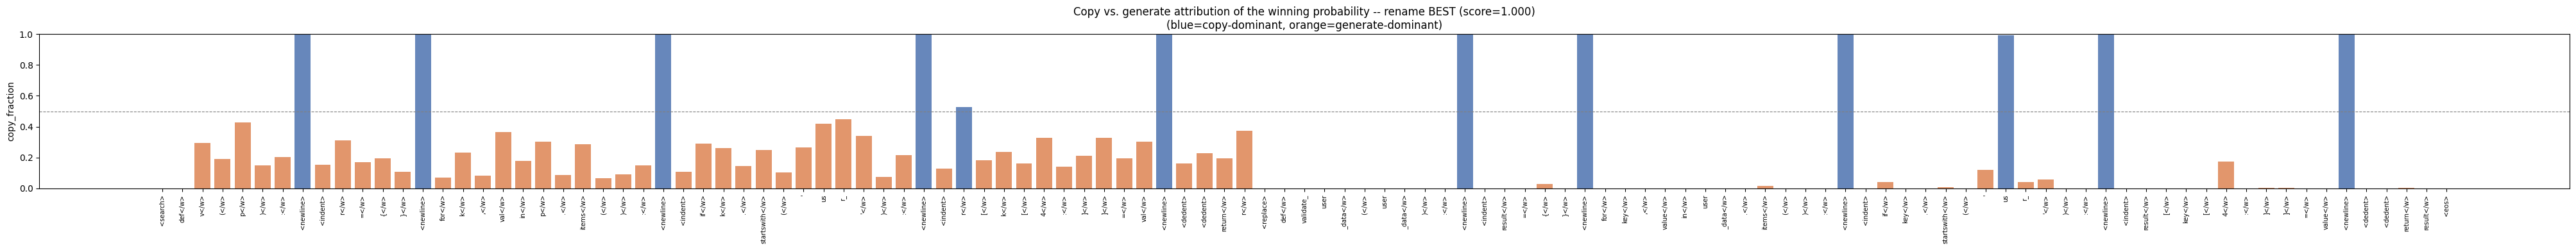

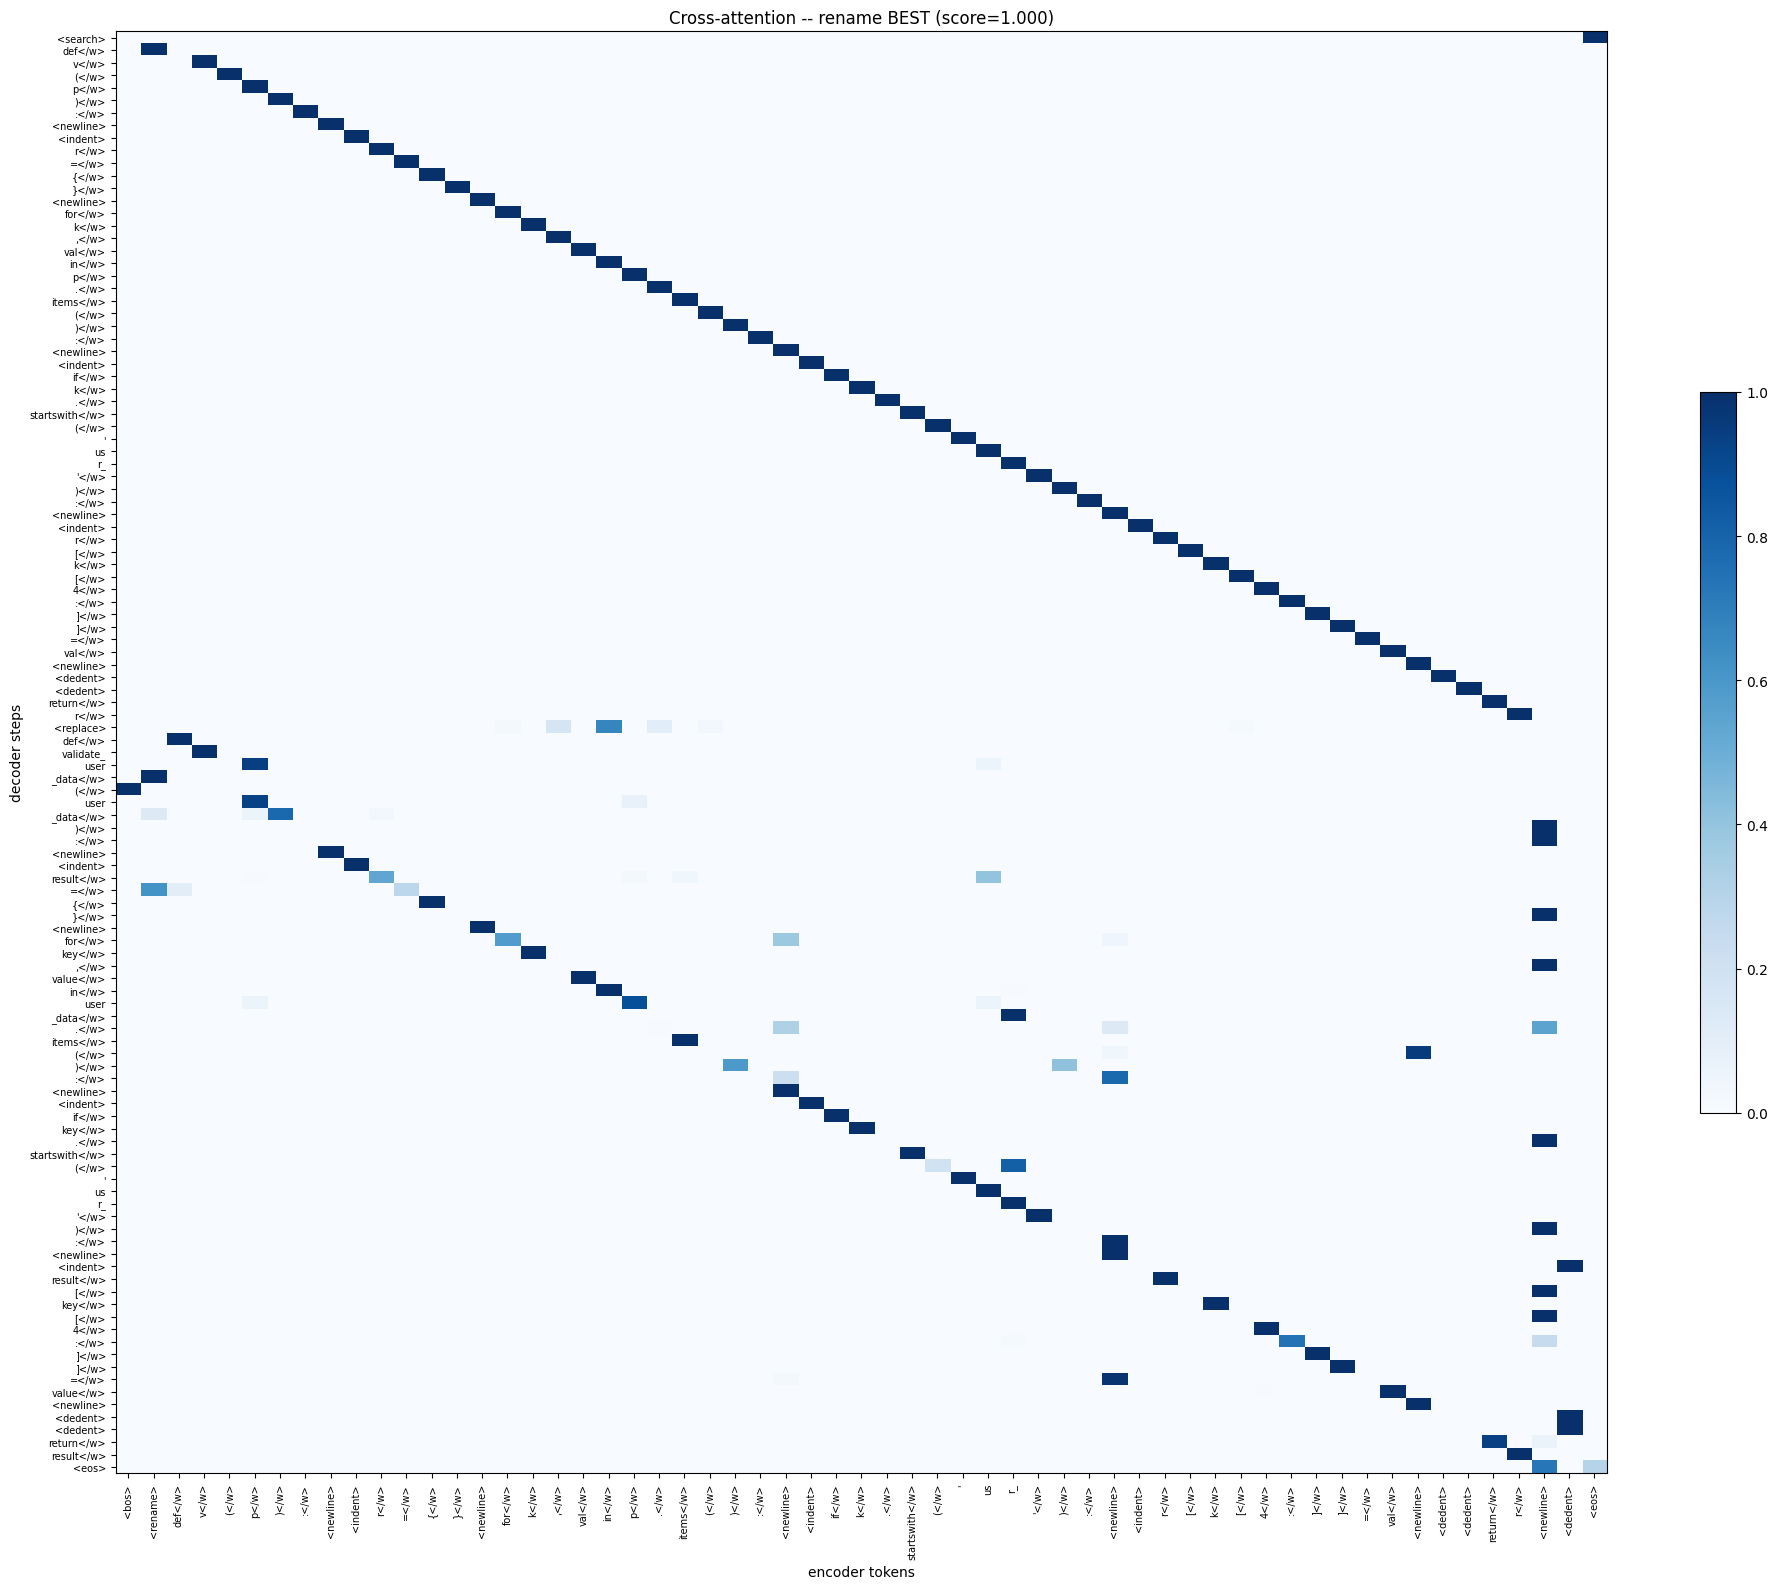

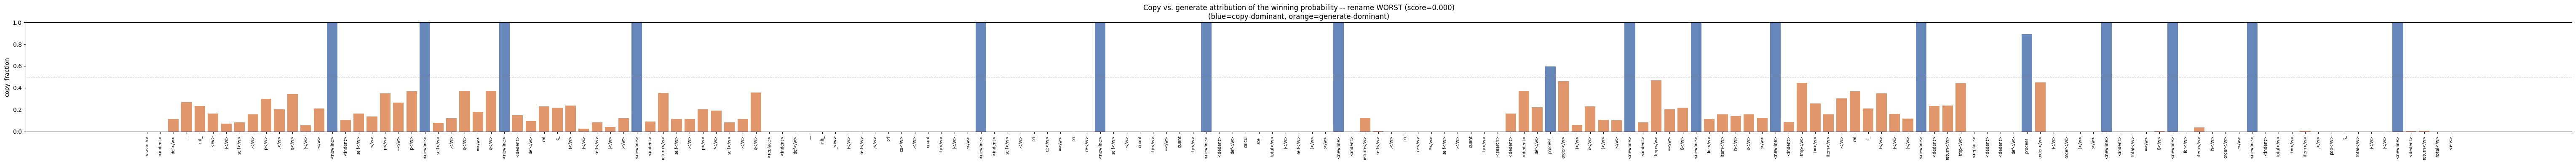

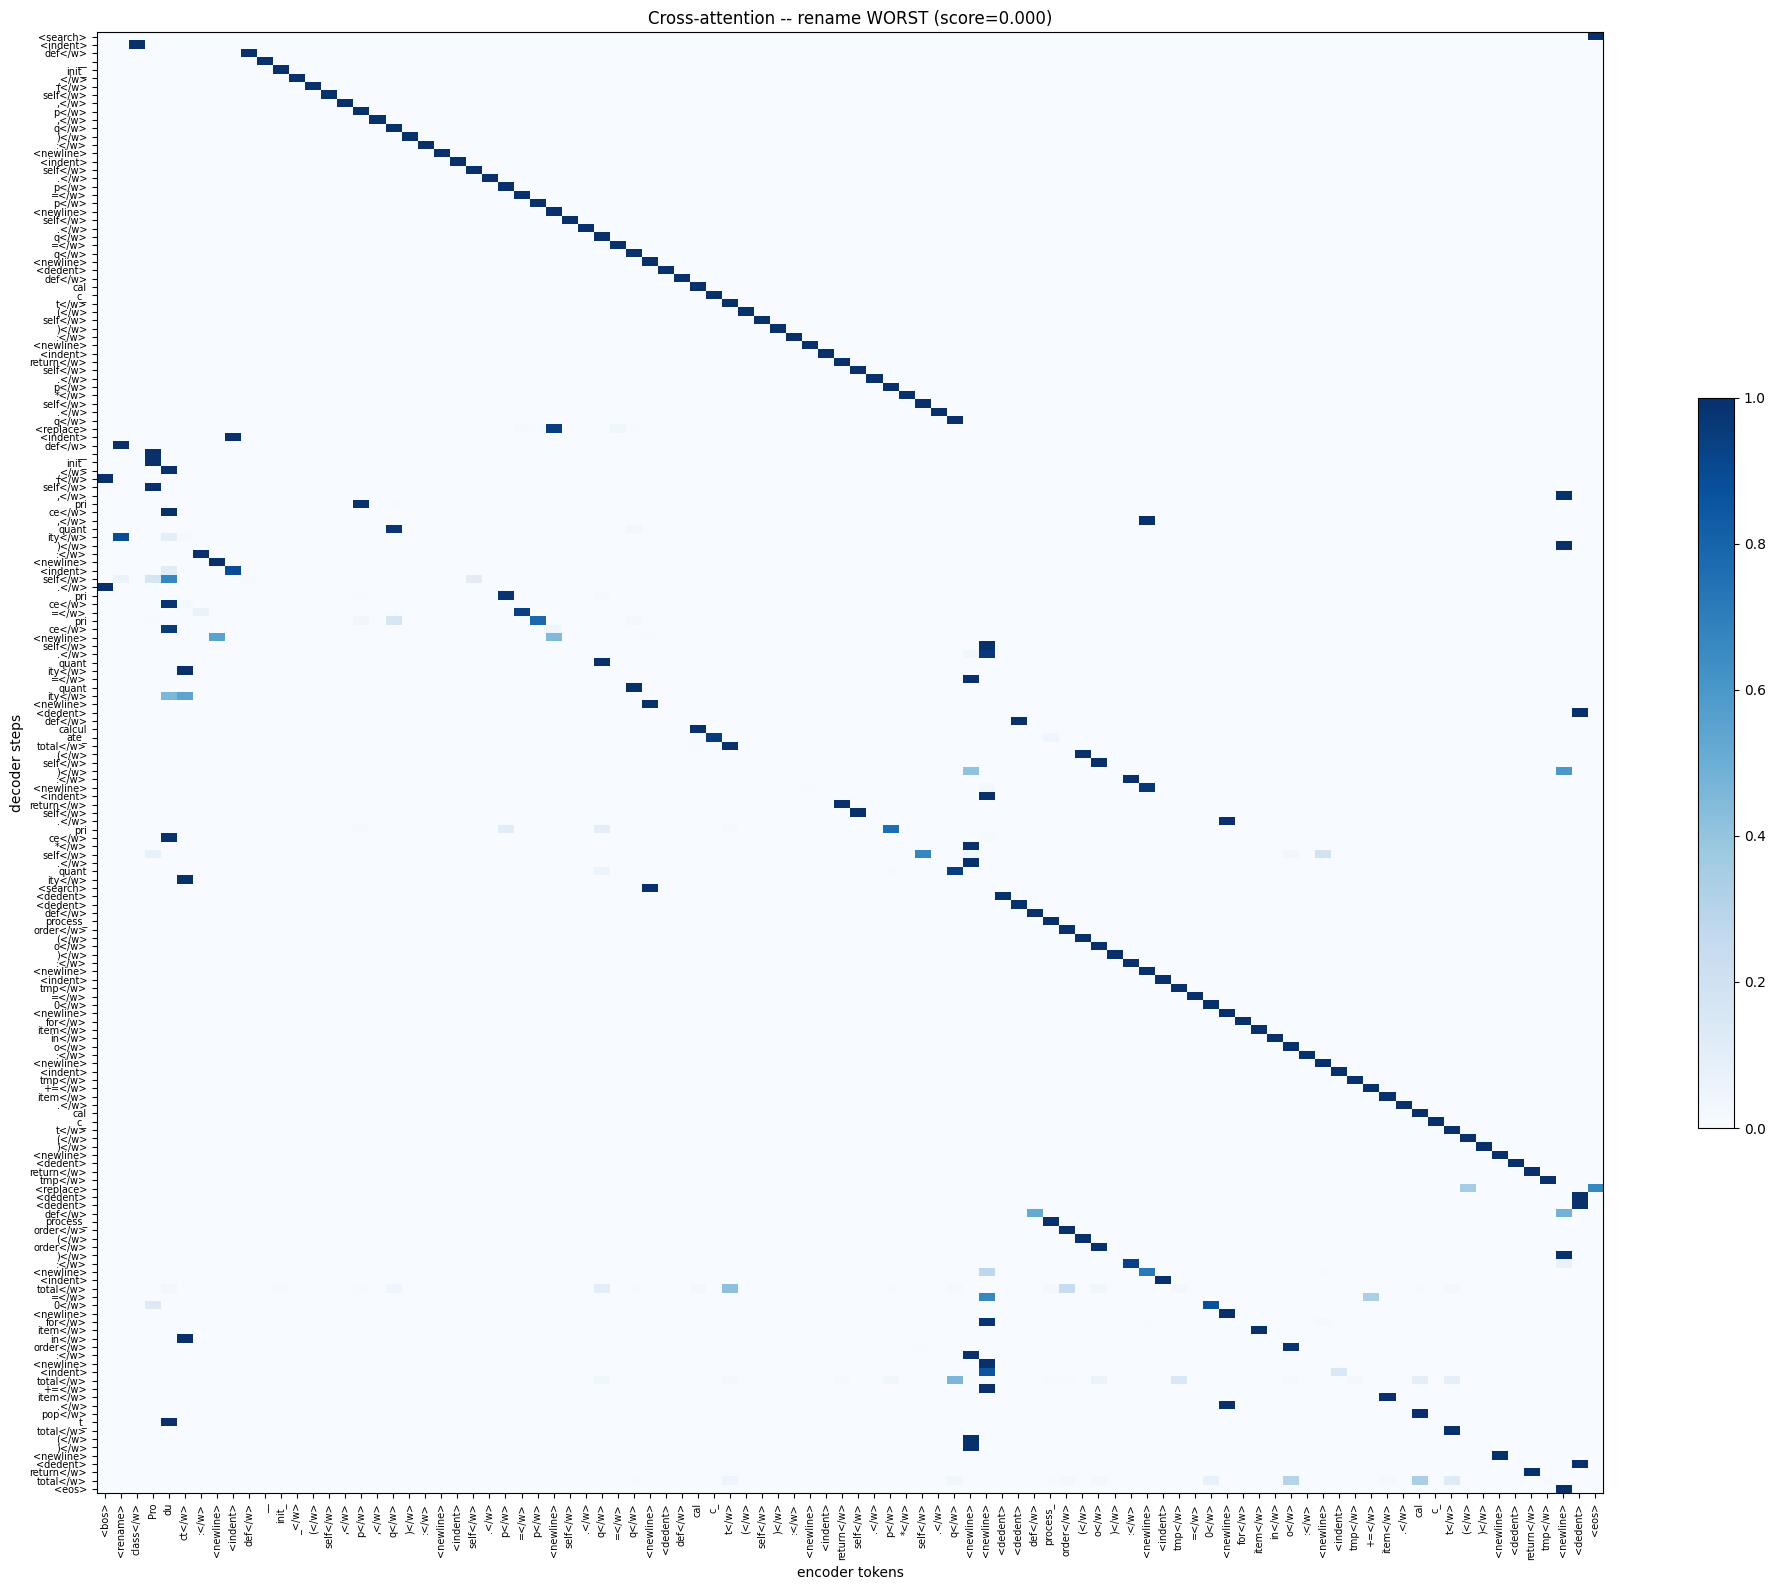

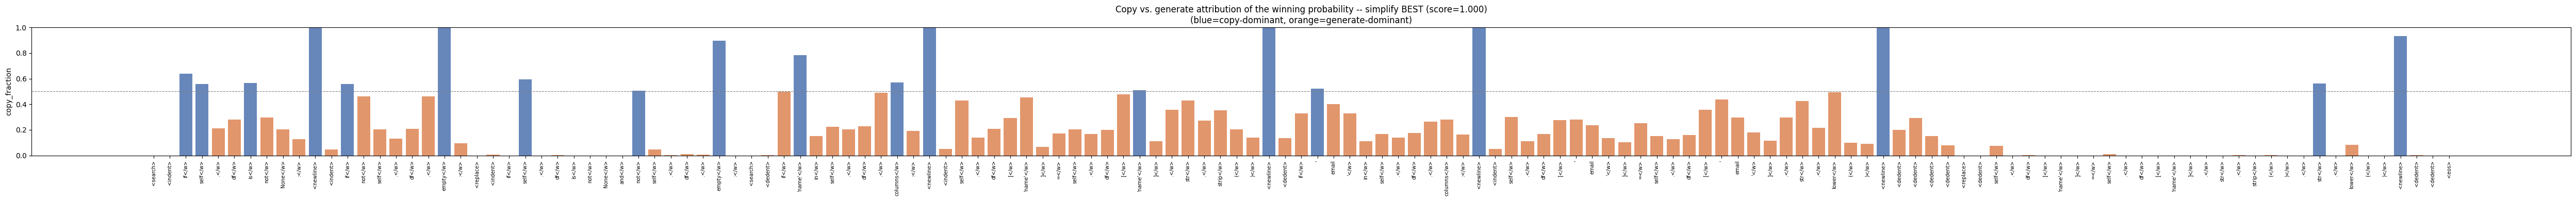

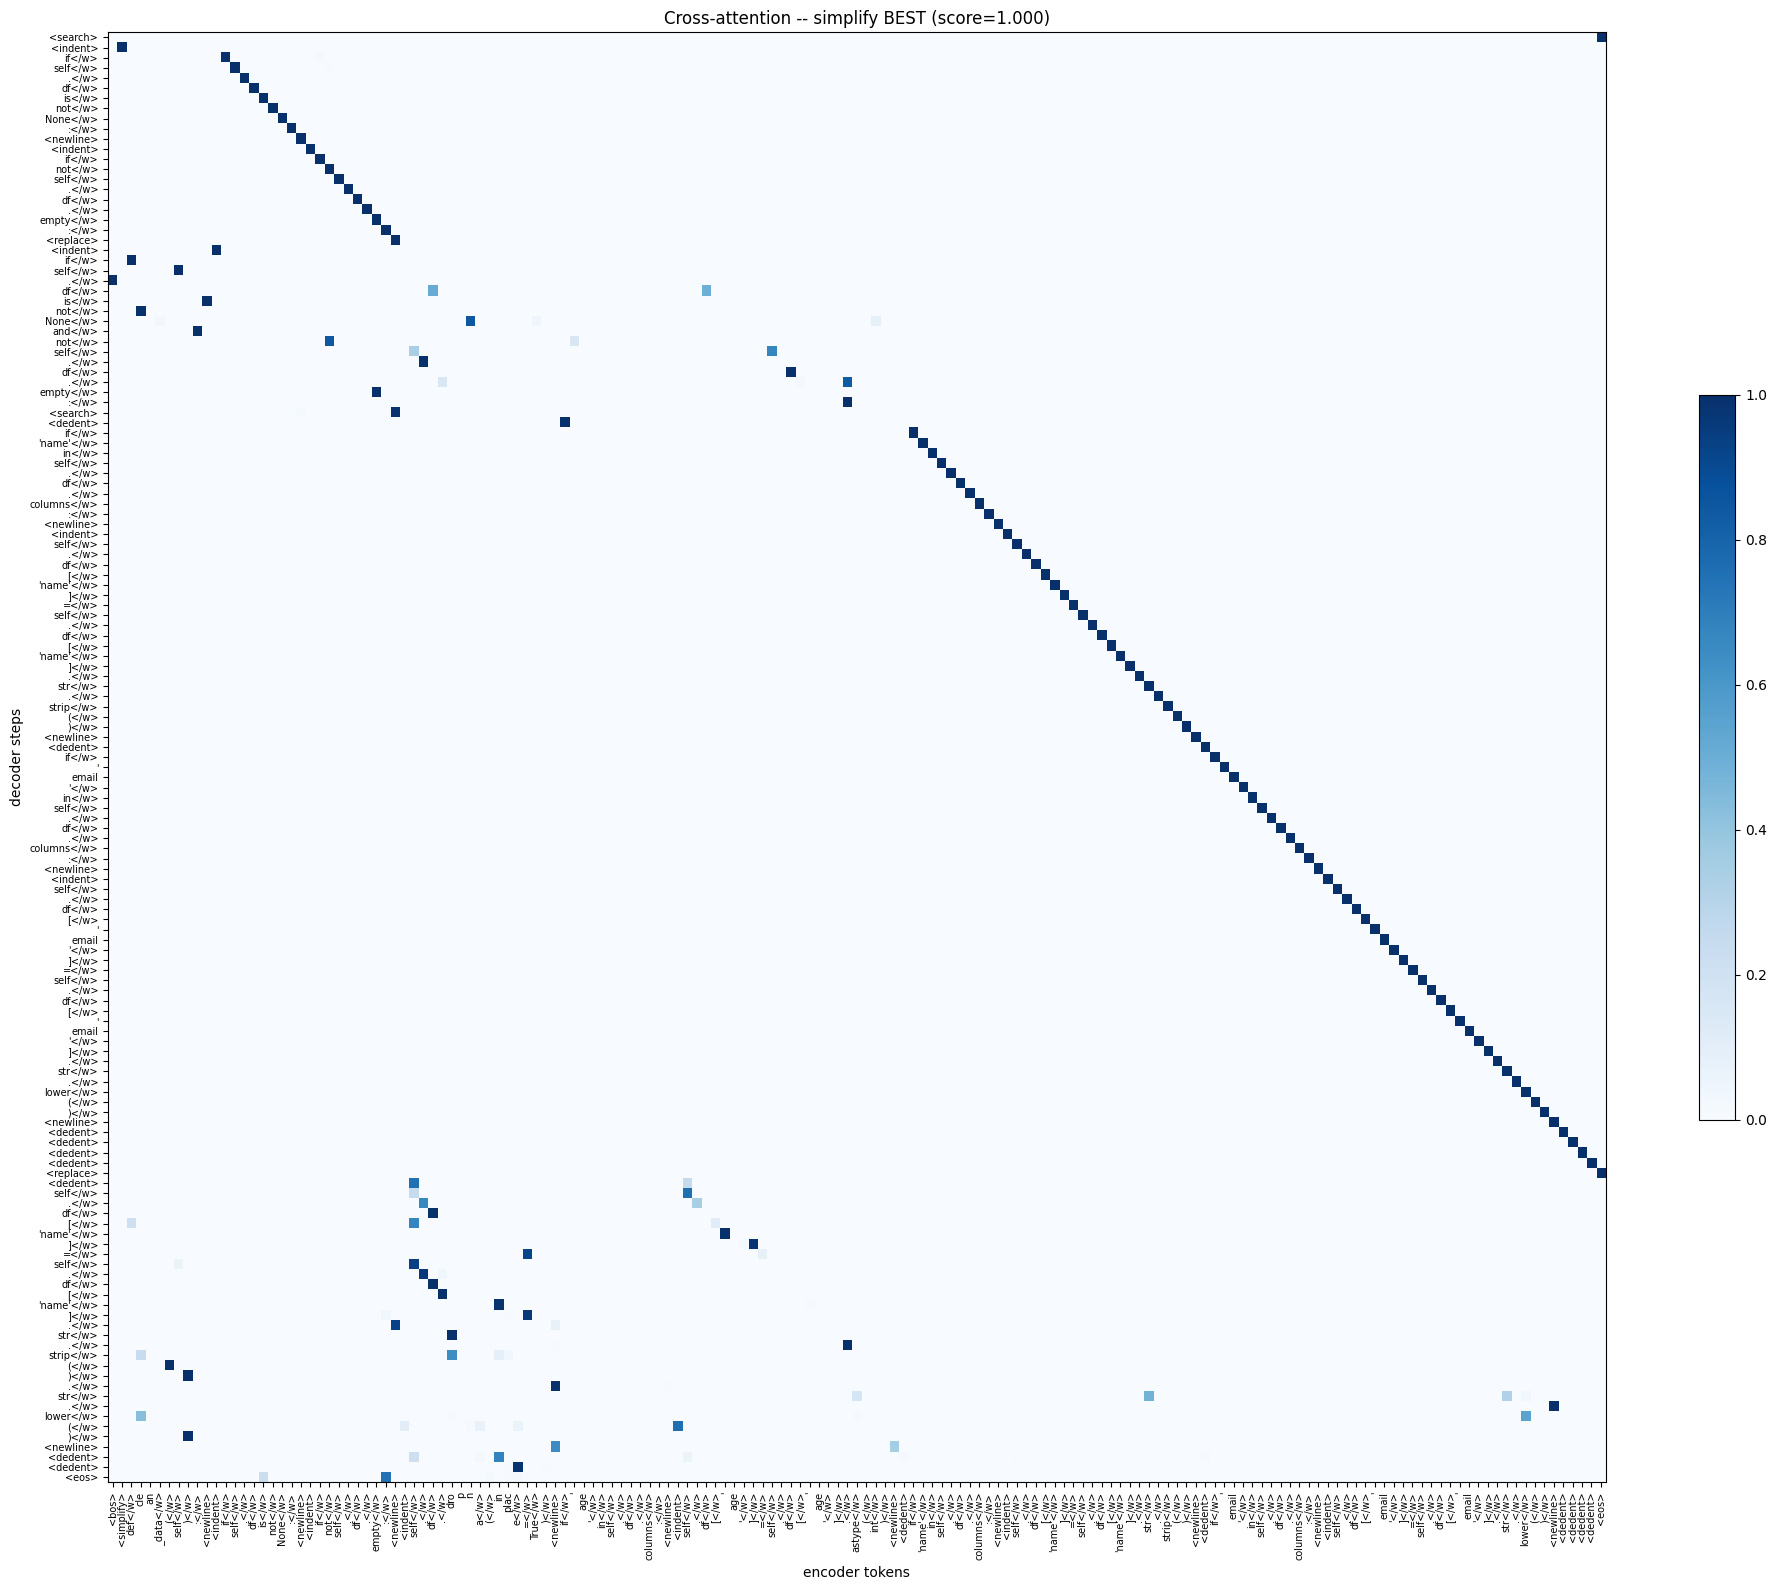

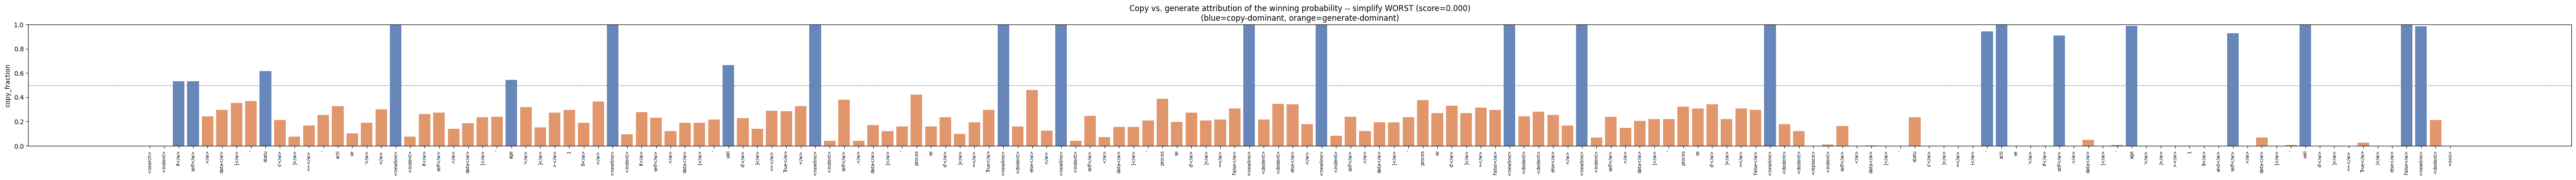

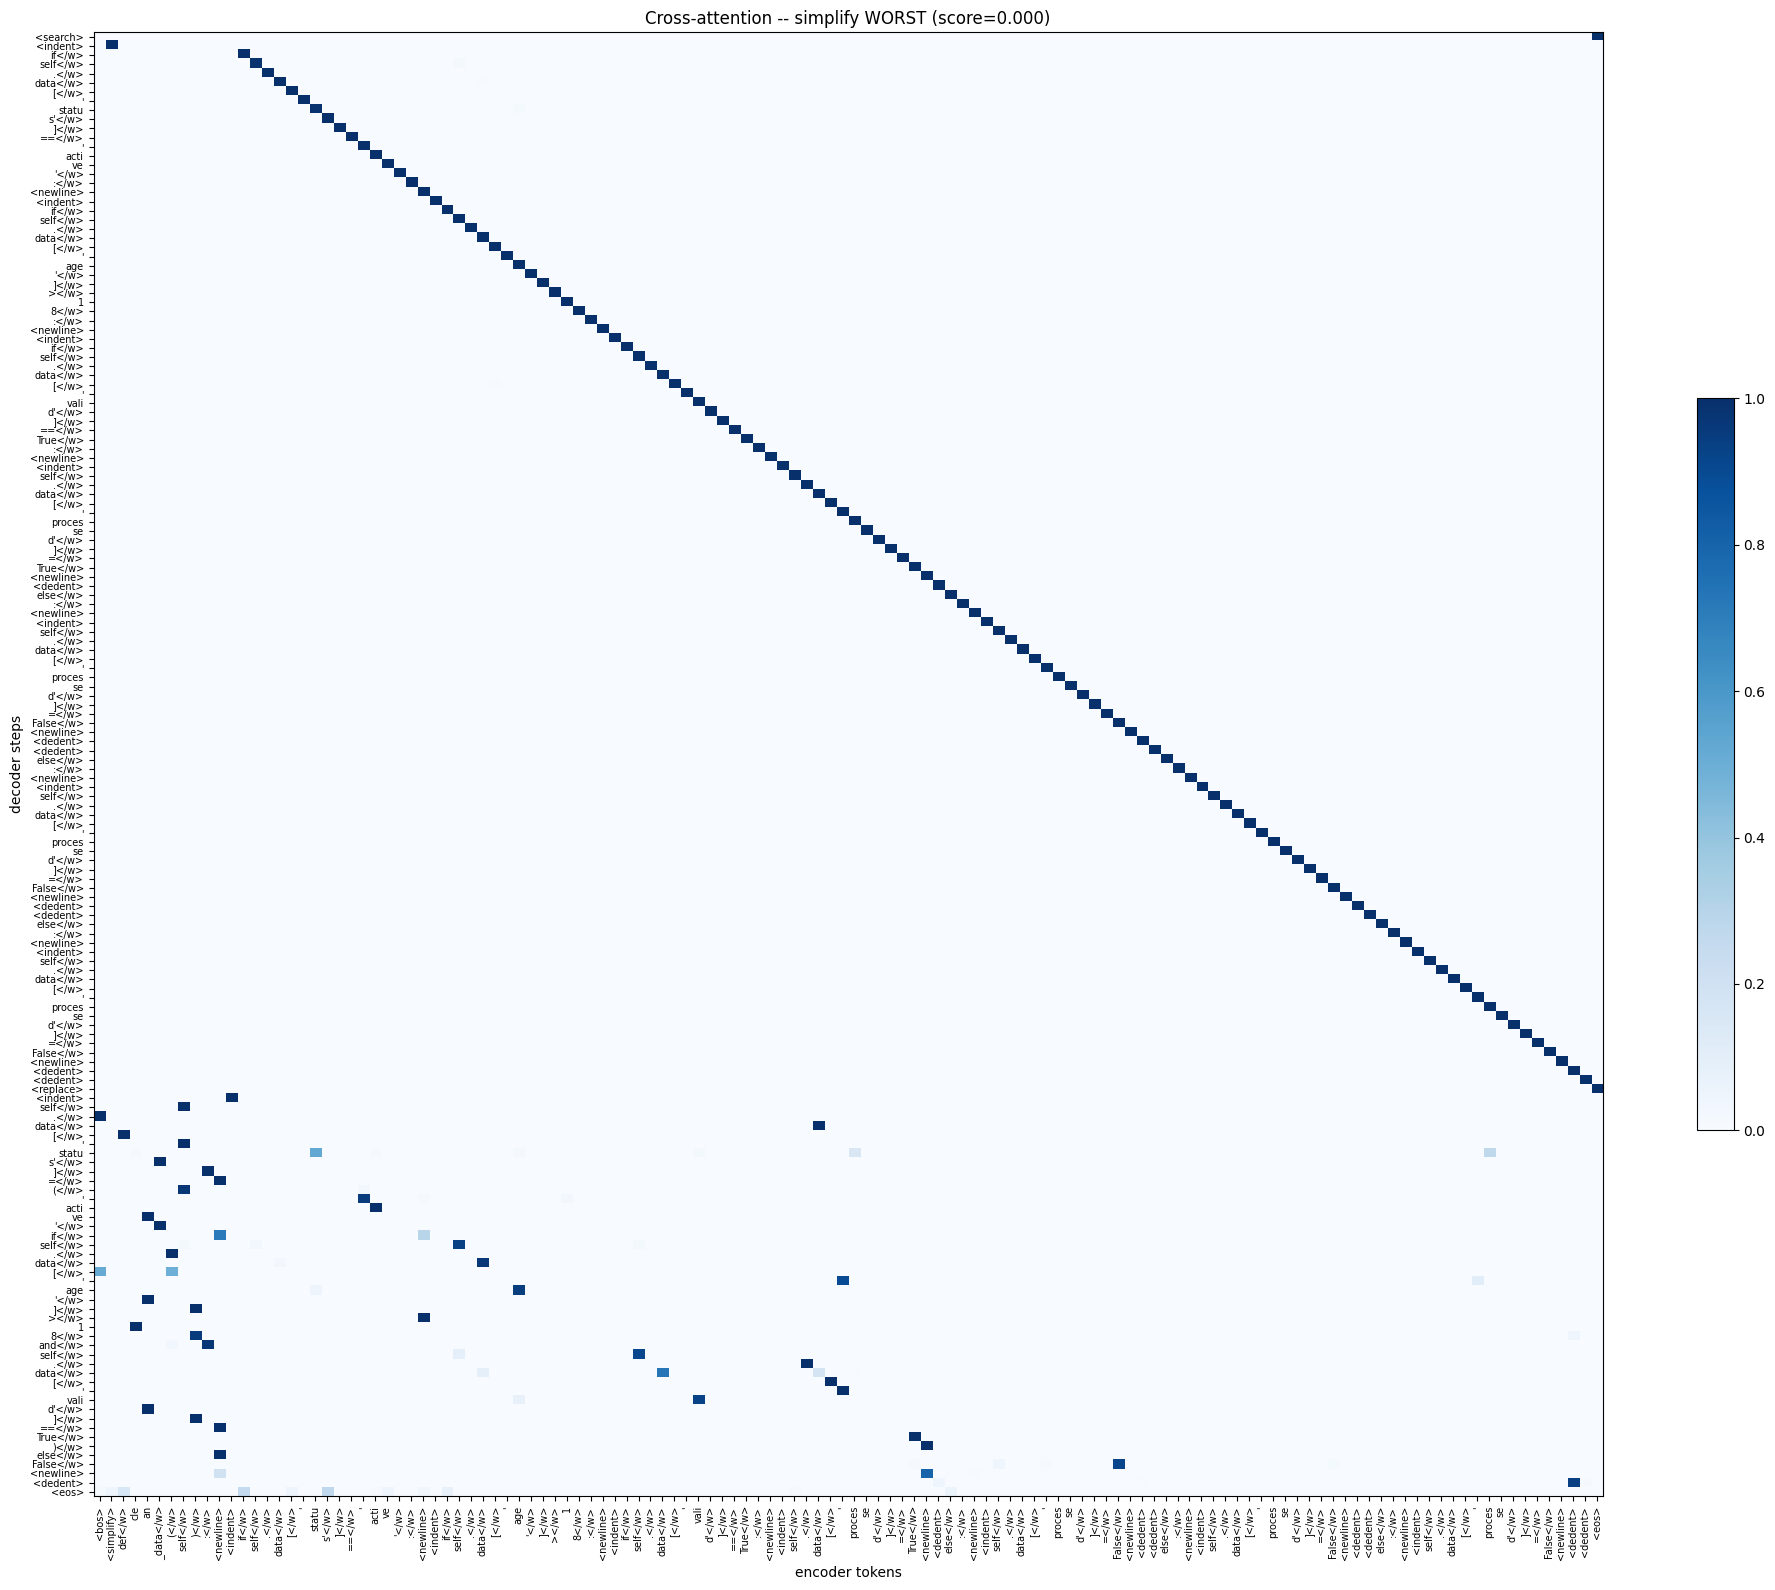

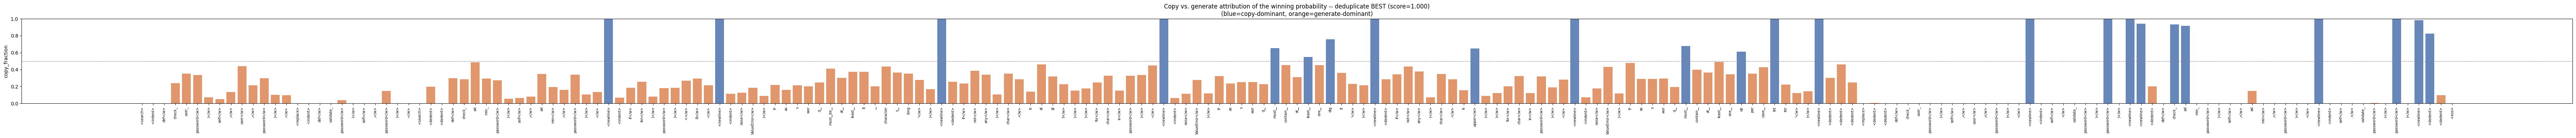

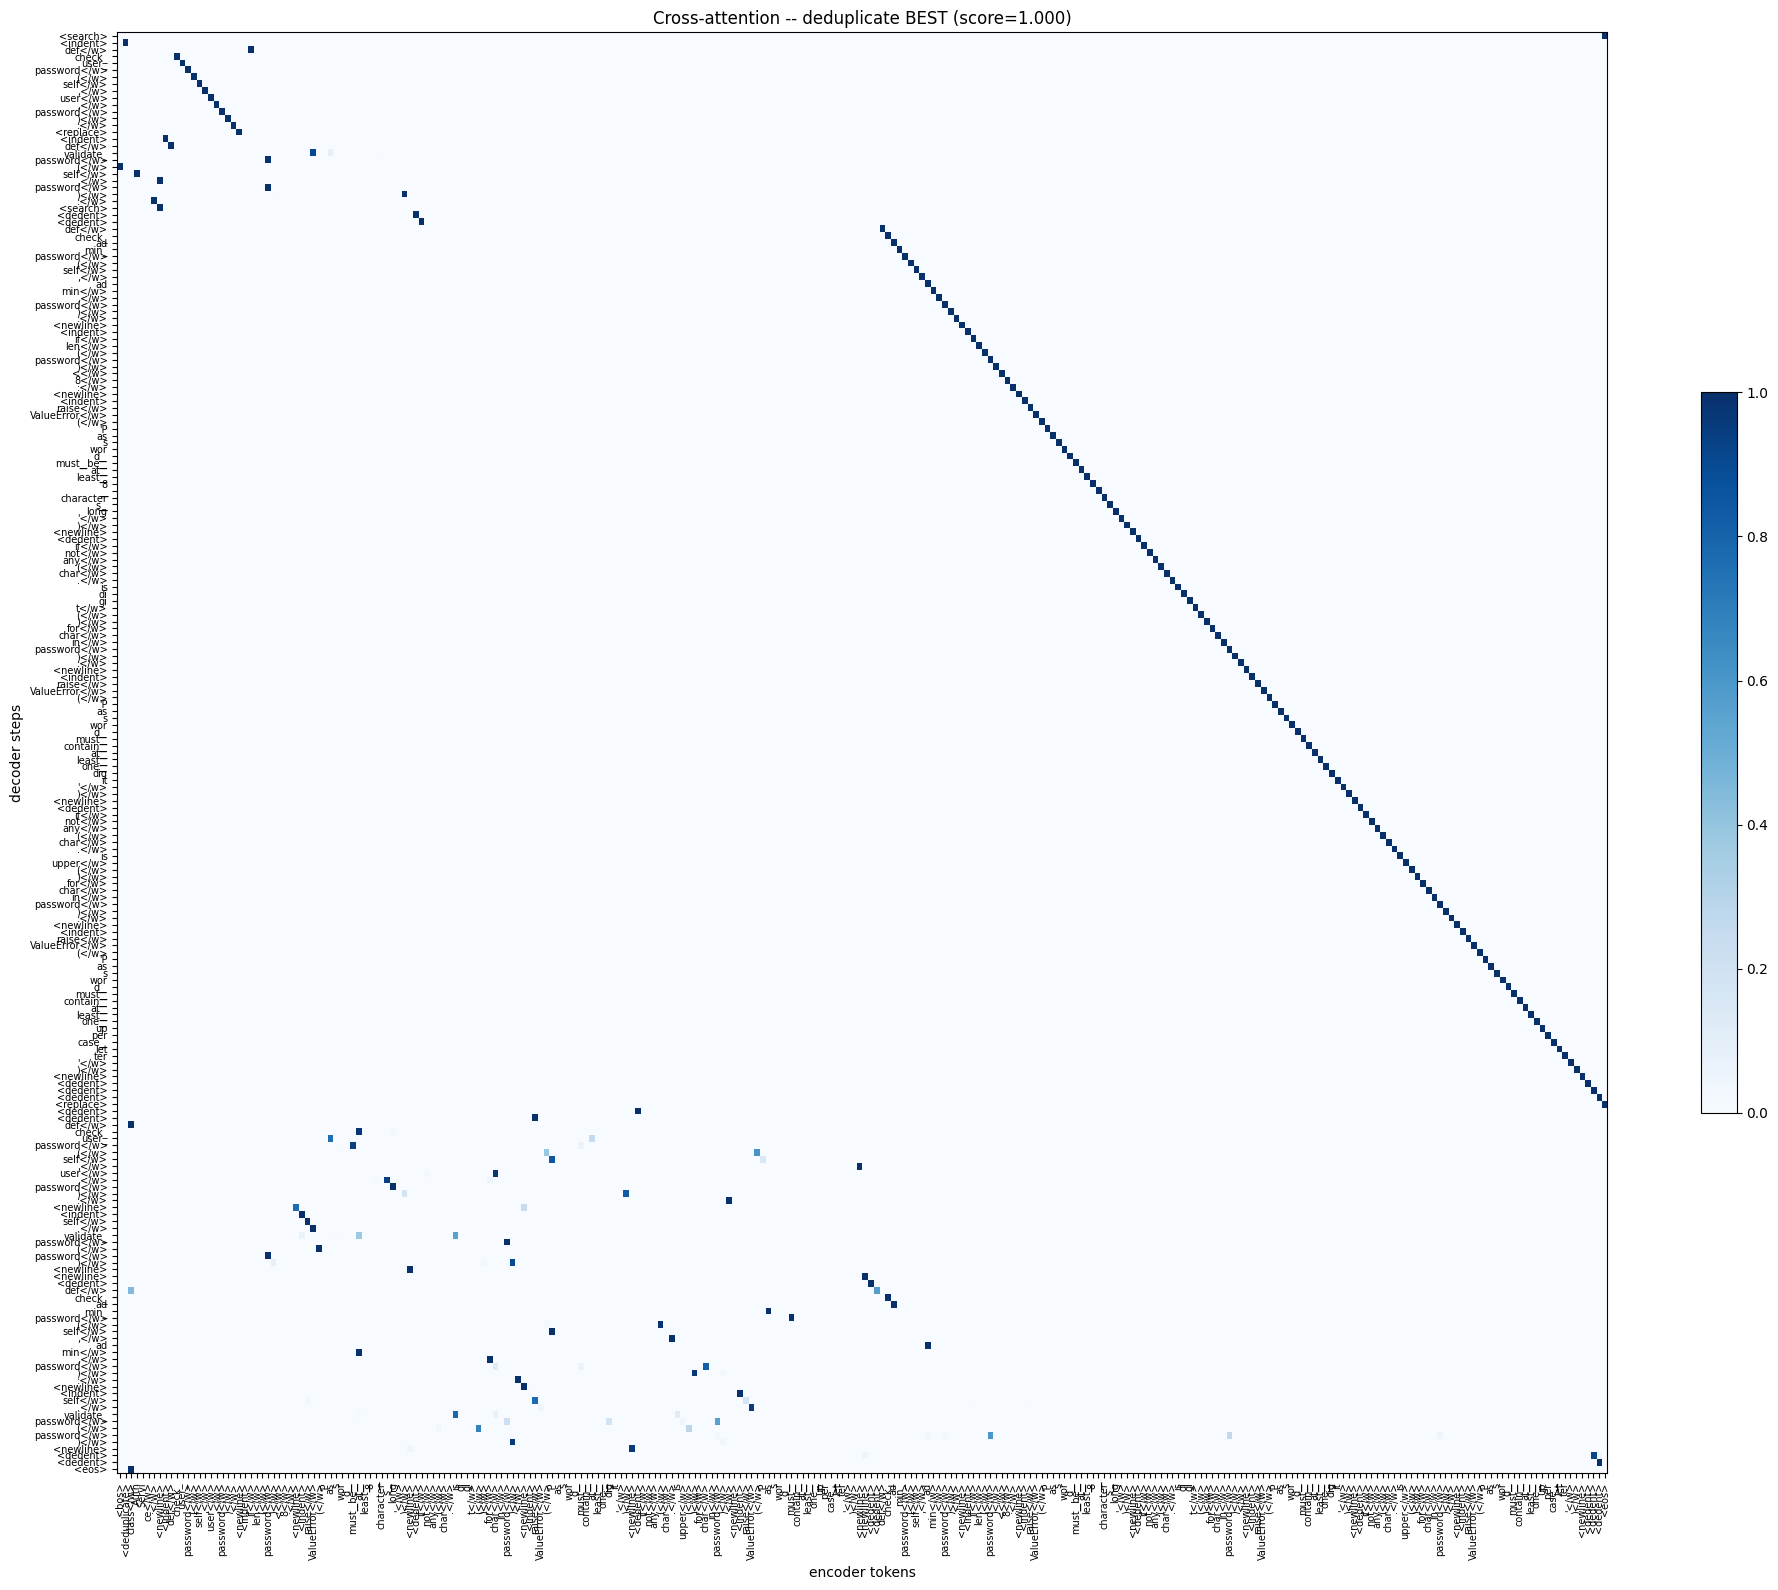

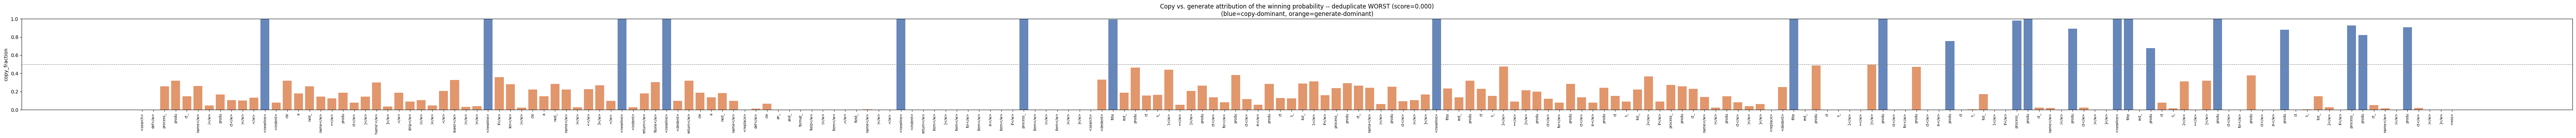

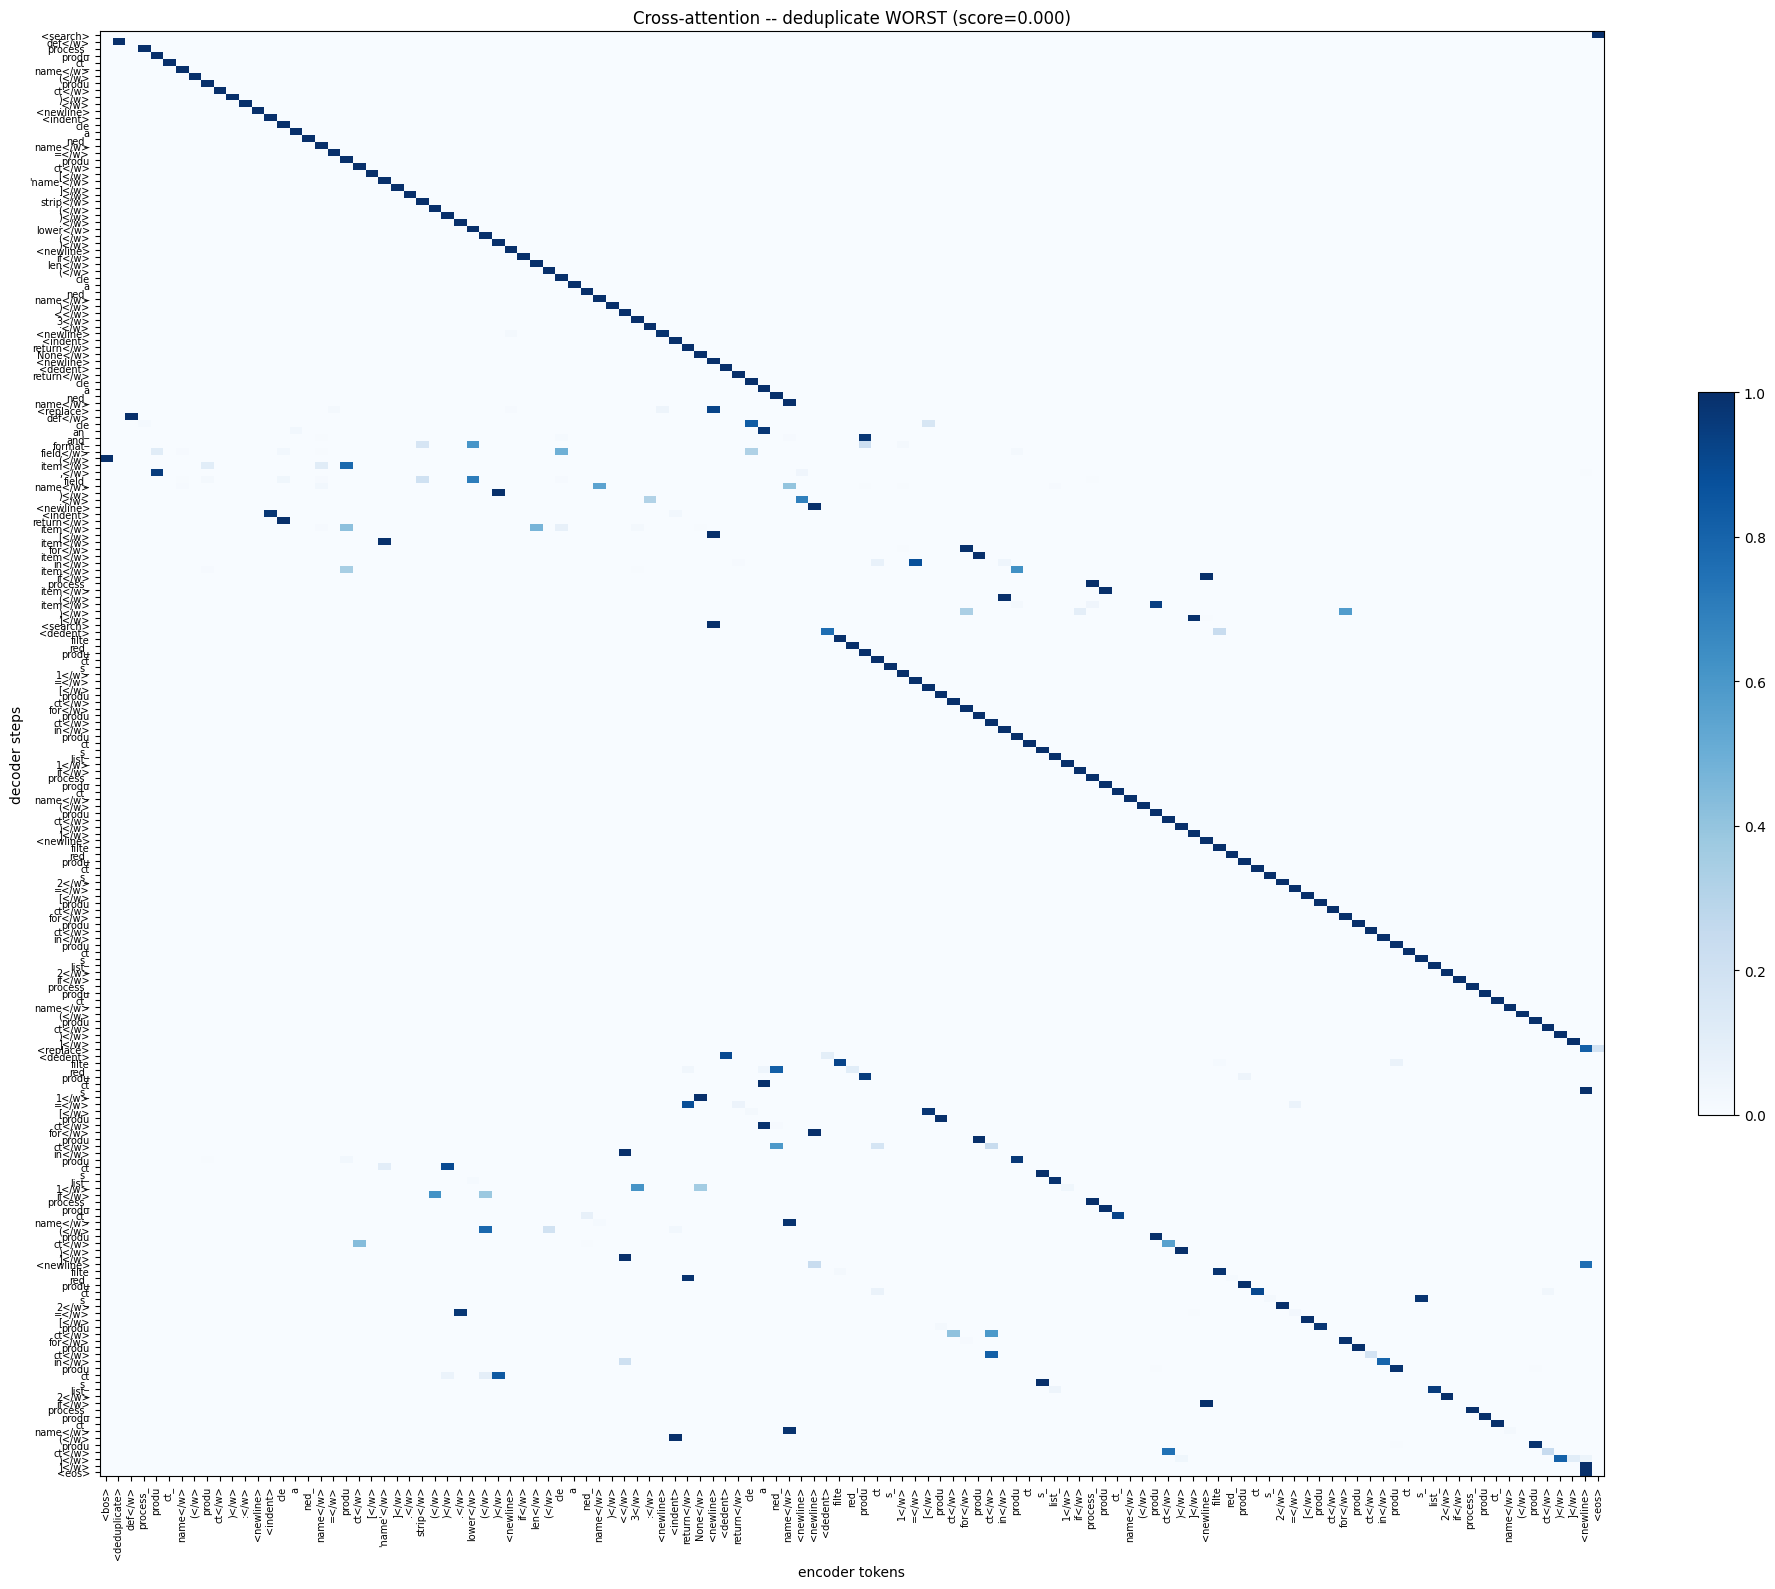

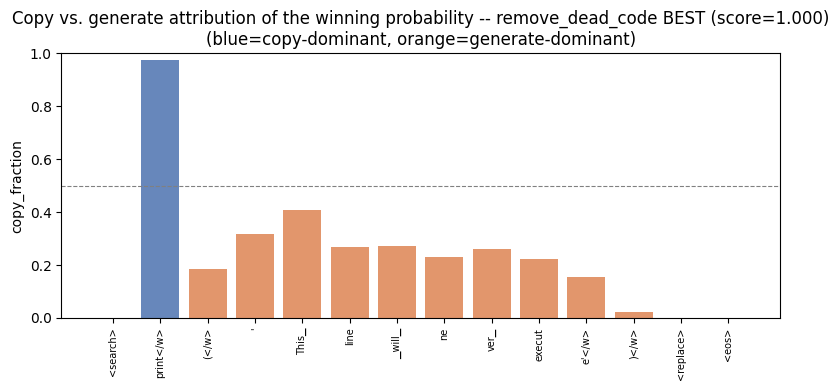

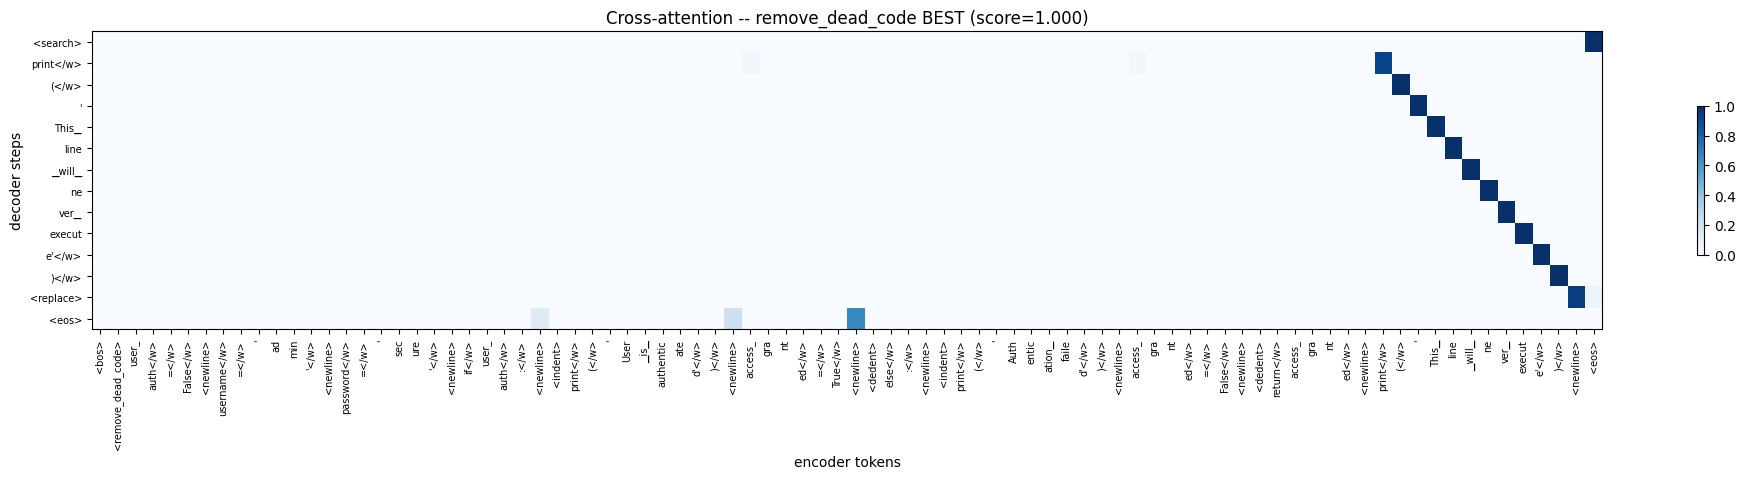

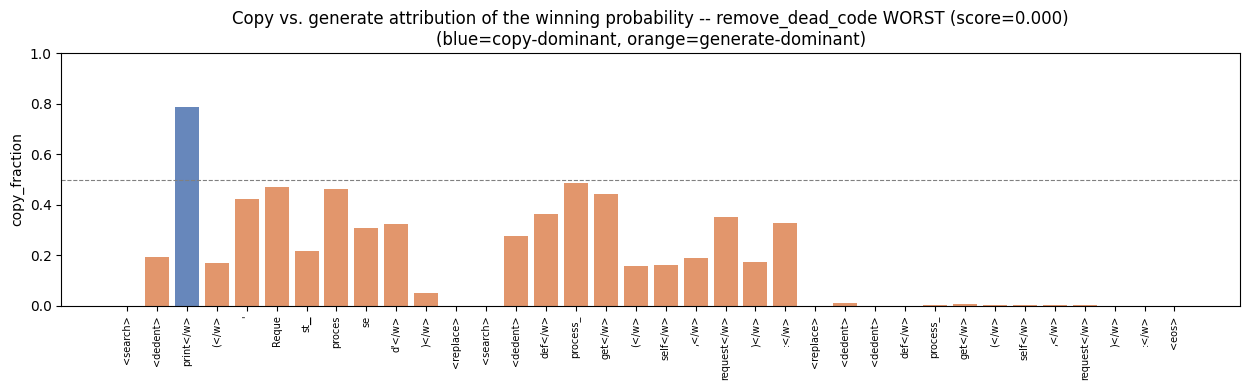

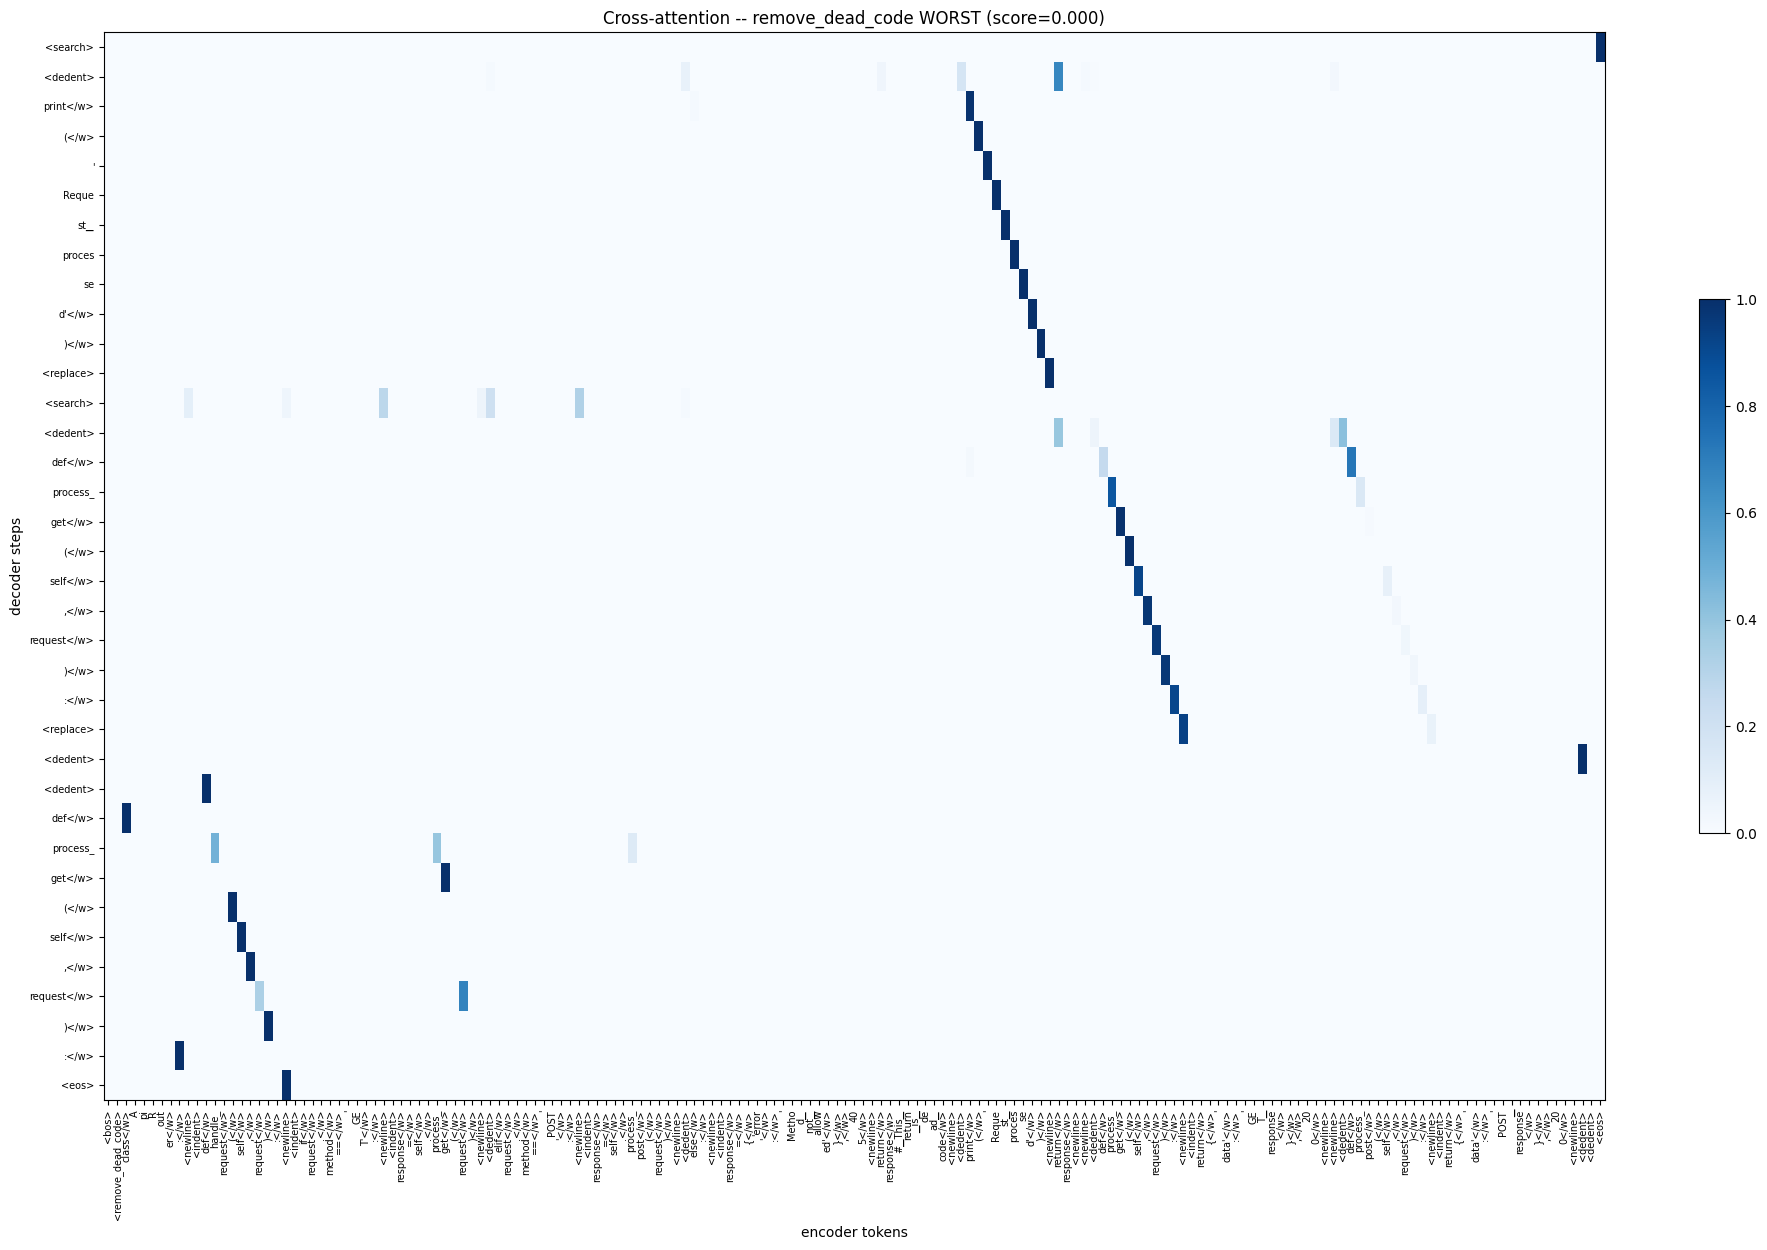

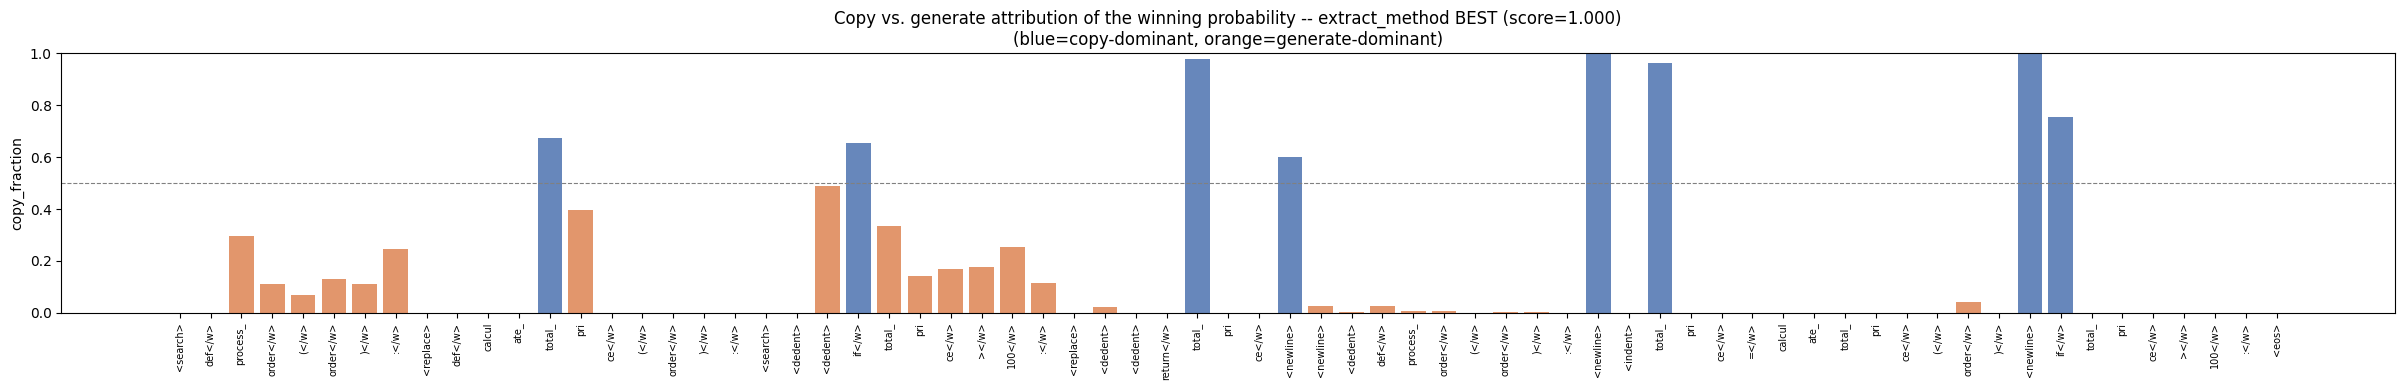

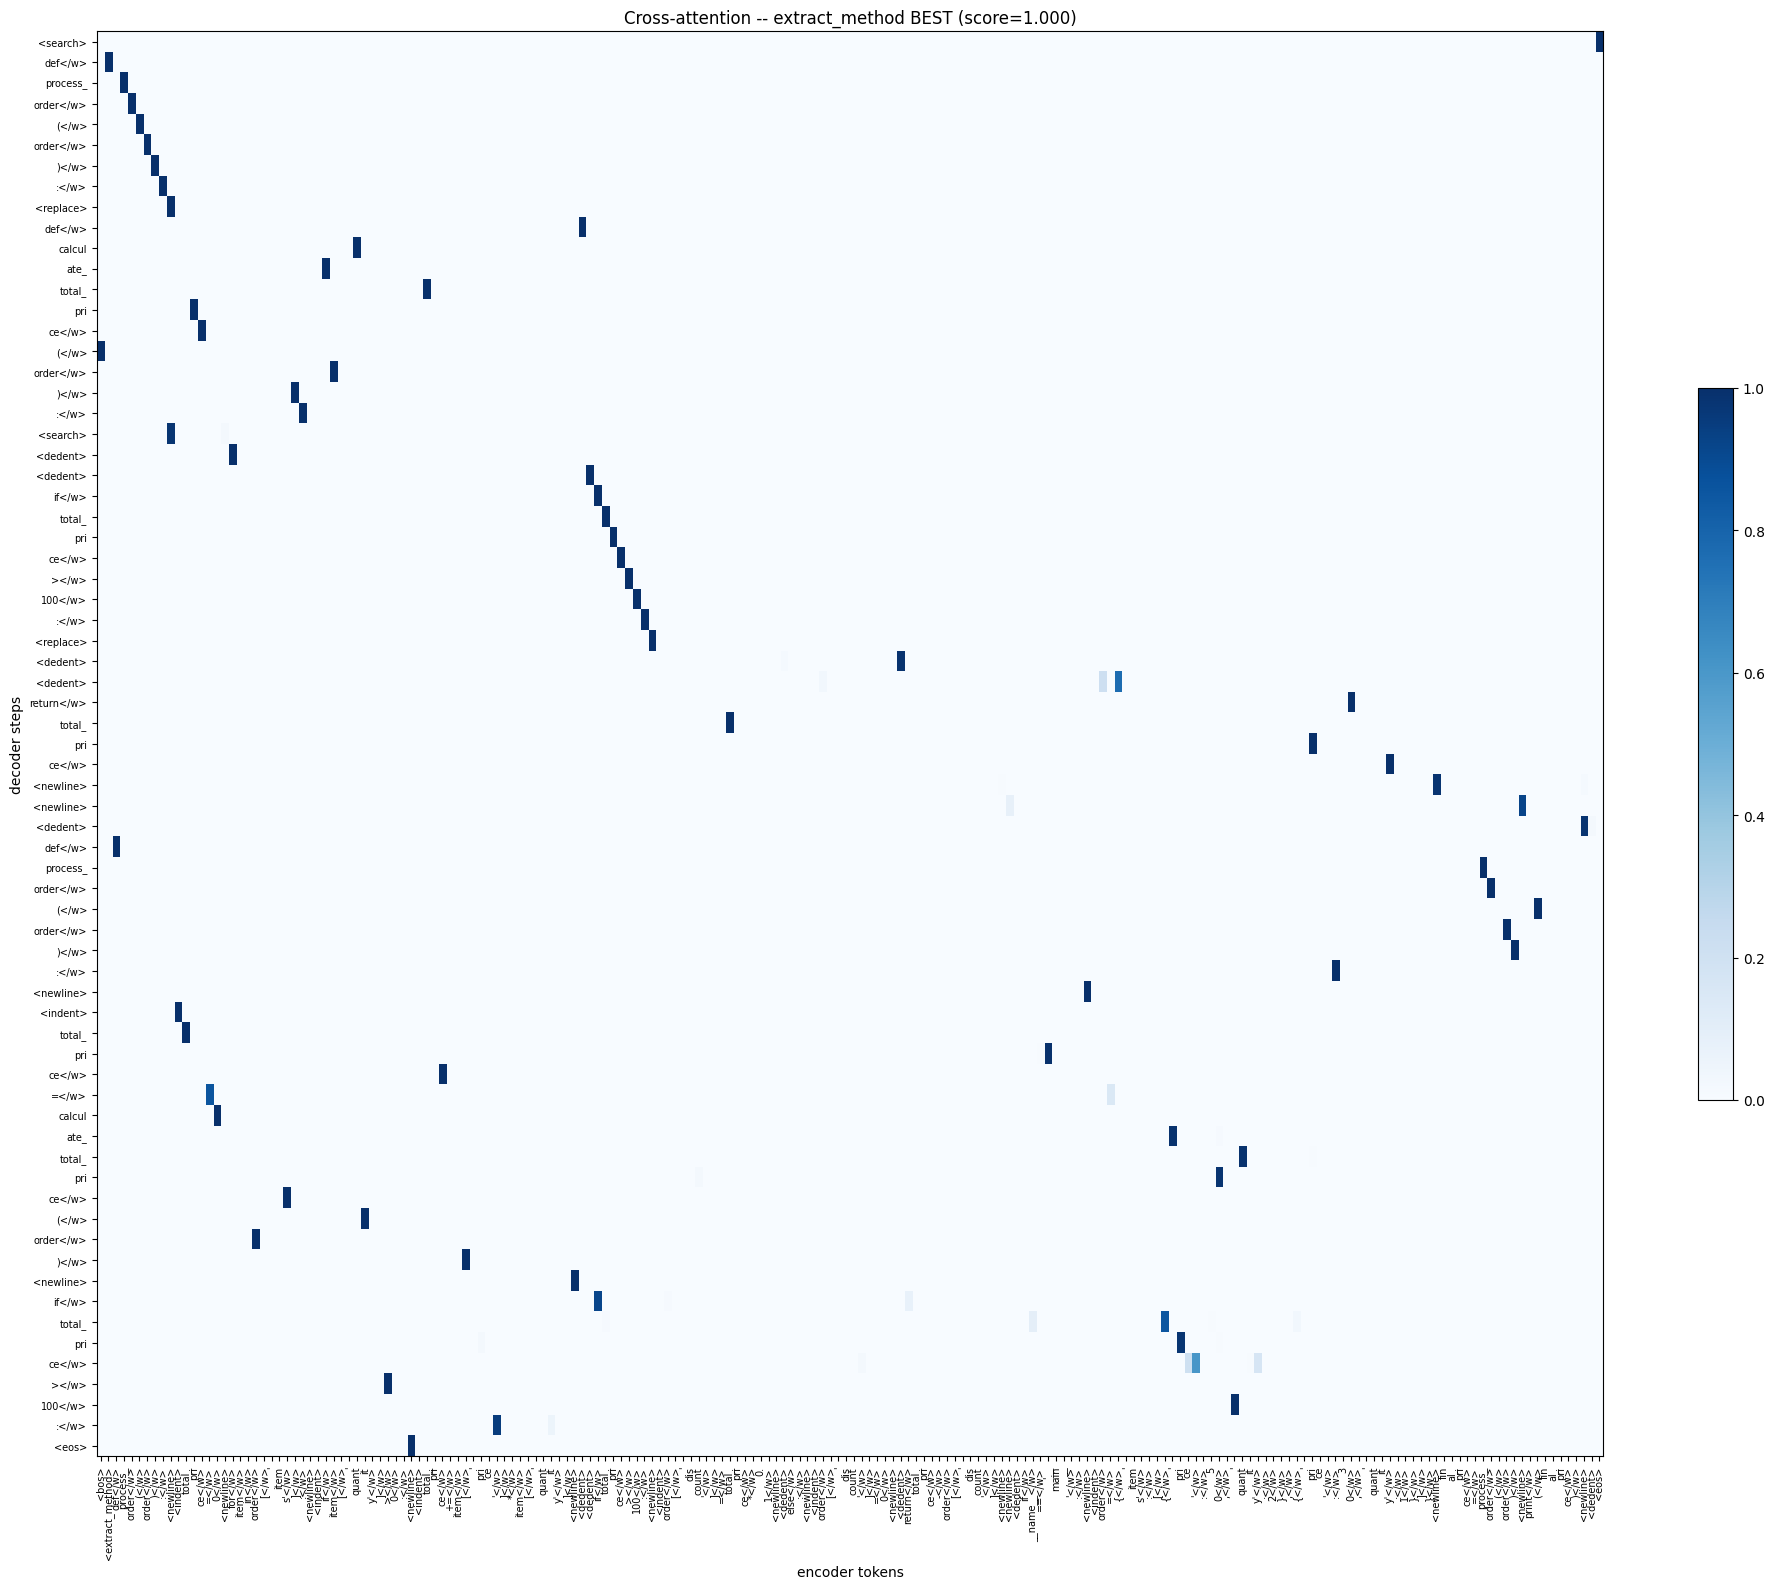

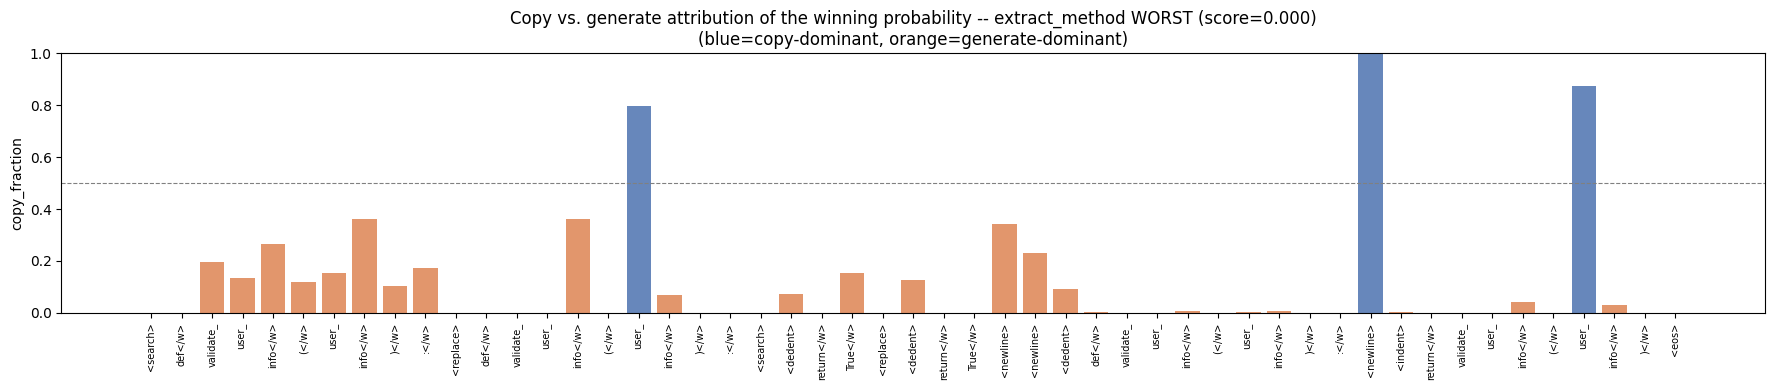

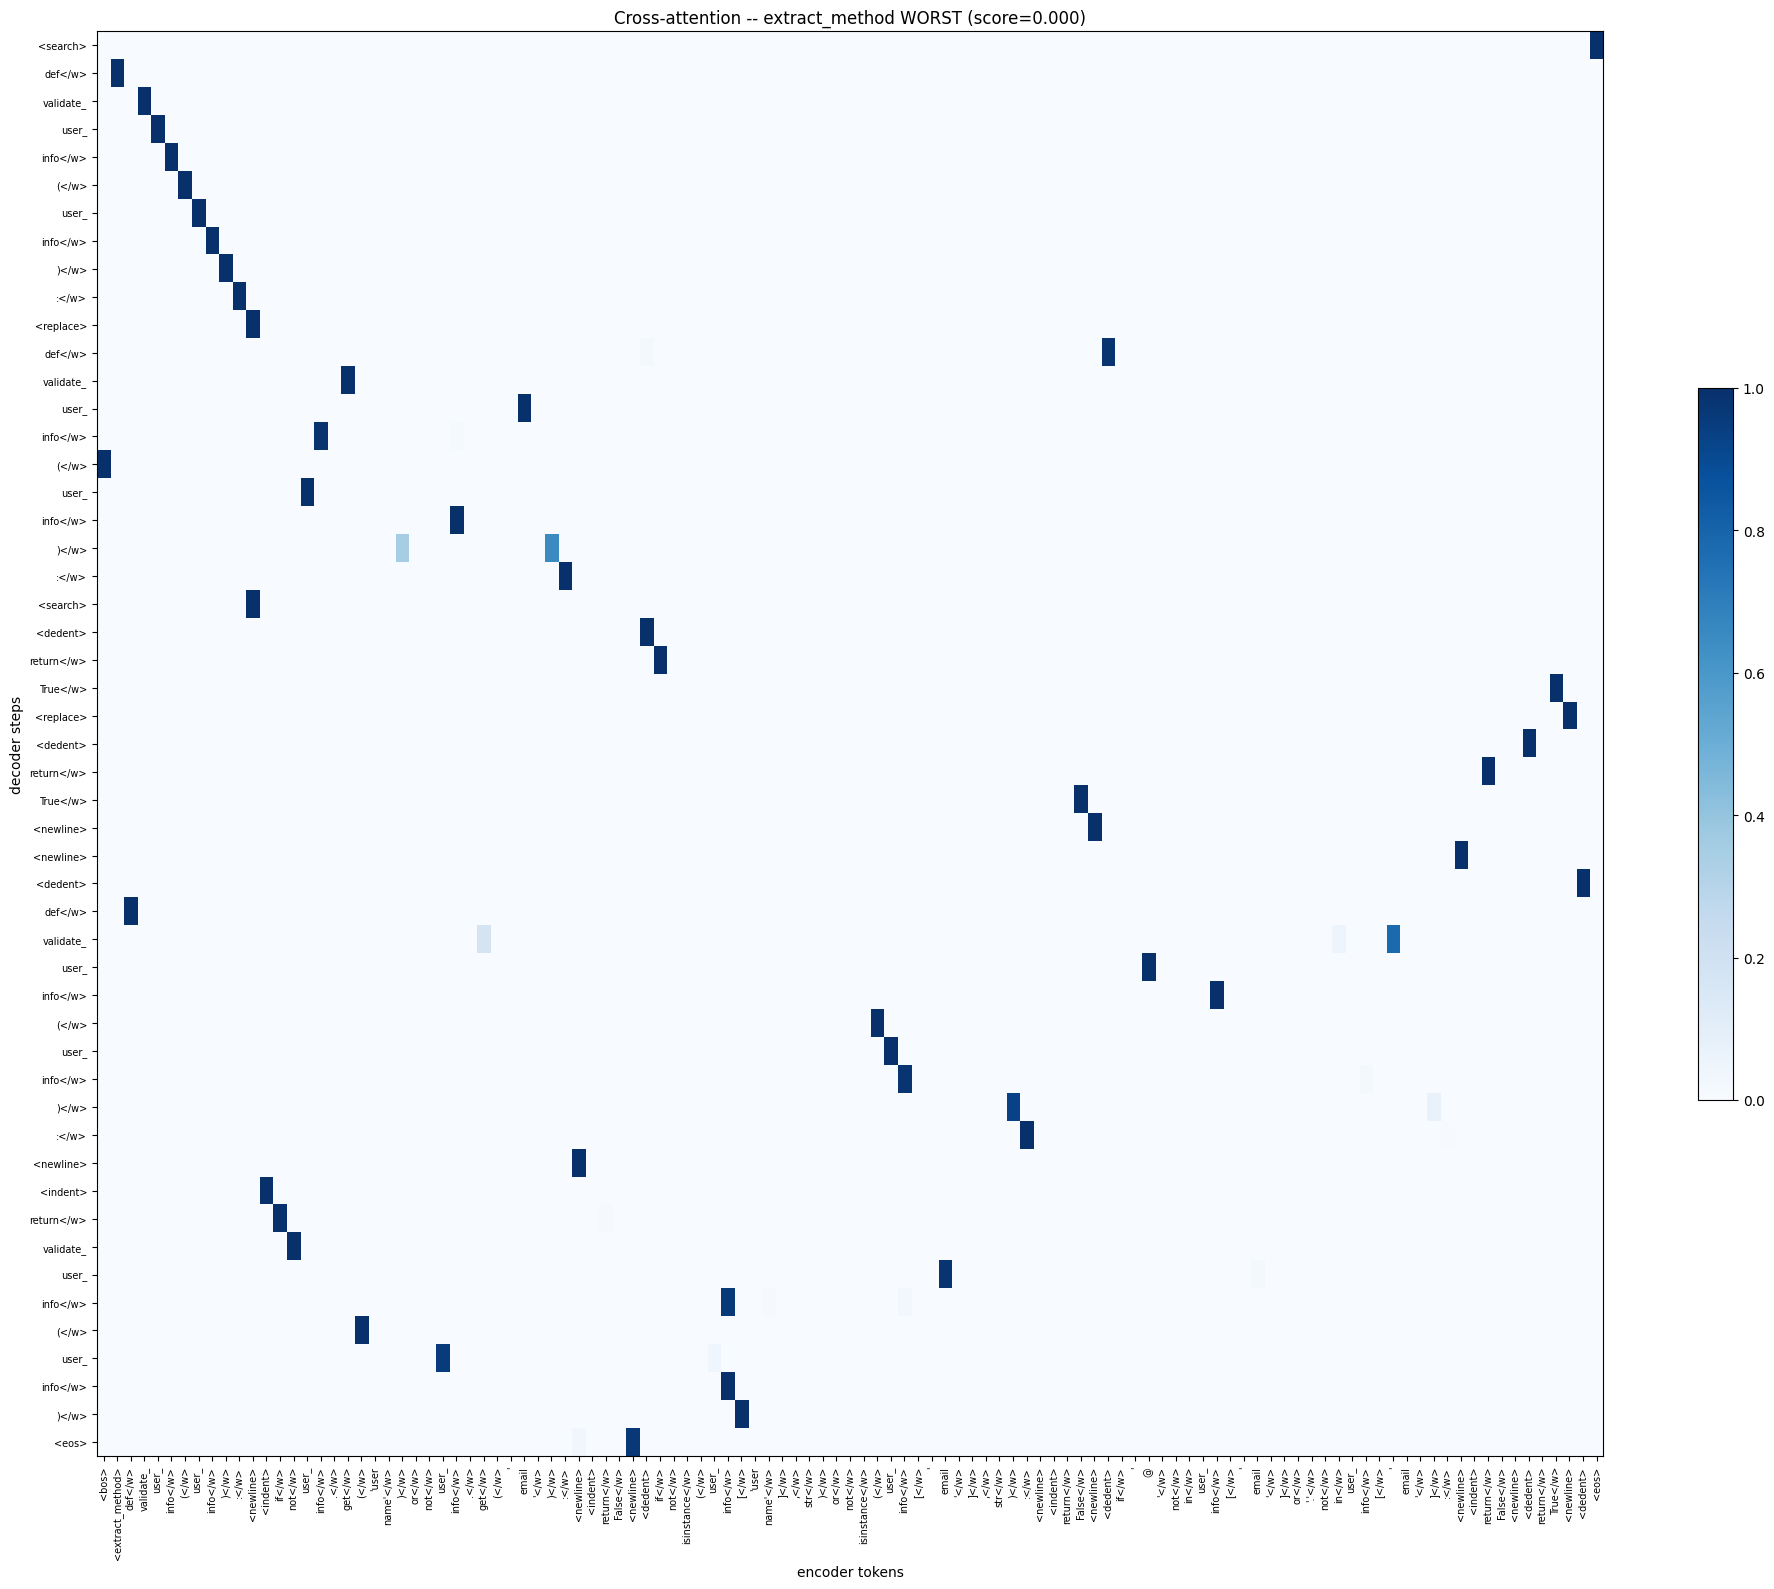

In [21]:
def compute_copy_fraction(tokens, pgens, confs, attn, enc_ids):
    """Per-decode-step fraction of the winning probability that came from the
    copy channel, reconstructed algebraically (replays copy_pointer.py's
    scatter_add by hand over the collected attention weights -- no model
    access needed beyond what greedy_decode already returns):

      P_copy[token]     = sum of attn[step] over encoder positions holding
                           that exact token id
      copy_contribution = (1 - p_gen) * P_copy[token]
      copy_fraction     = copy_contribution / P_final[token]   (== confs[step],
                           since the chosen token is always the argmax)

    Clamped to [0, 1] to absorb float noise from the algebraic reconstruction.
    """
    enc_ids_arr = np.asarray(enc_ids)
    pred_tokens = tokens[1:]  # tokens[0] is <bos>; aligns with pgens/confs/attn
    fractions = []
    for step, tok_id in enumerate(pred_tokens):
        p_gen = pgens[step]
        p_final = confs[step]
        p_copy_token = float(attn[step][enc_ids_arr == tok_id].sum())
        copy_contribution = (1.0 - p_gen) * p_copy_token
        frac = copy_contribution / p_final if p_final > 1e-9 else 0.0
        fractions.append(min(max(frac, 0.0), 1.0))
    return fractions


def plot_copy_fraction_and_attention(trace, tokenizer, save_prefix):
    rec, label, pgens, attn, confs = trace["rec"], trace["label"], trace["pgens"], trace["attn"], trace["confs"]
    tokens = rec["pred_dec"]
    token_strs = [tokenizer.id_to_token(t) for t in tokens[1:]]  # tokens[0] is <bos>; pgens/attn align with tokens[1:]
    enc_strs = [tokenizer.id_to_token(t) for t in rec["enc_ids"]]

    fractions = compute_copy_fraction(tokens, pgens, confs, attn, rec["enc_ids"])
    fig, ax = plt.subplots(figsize=(max(8, len(fractions) * 0.35), 4))
    xs = range(len(fractions))
    colors = ["#4C72B0" if f > 0.5 else "#DD8452" for f in fractions]
    ax.bar(xs, fractions, color=colors, alpha=0.85)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xticks(list(xs)); ax.set_xticklabels(token_strs, rotation=90, fontsize=7)
    ax.set_ylabel("copy_fraction"); ax.set_ylim(0, 1)
    ax.set_title(f"Copy vs. generate attribution of the winning probability -- {label}\n"
                 f"(blue=copy-dominant, orange=generate-dominant)")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"explain_{save_prefix}_copyfrac.png", dpi=150)
    plt.show()

    fig, ax = plt.subplots(figsize=(min(len(enc_strs) * 0.4, 20), min(max(attn.shape[0], 1) * 0.35, 16)))
    im = ax.imshow(attn, aspect="auto", cmap="Blues", vmin=0, vmax=max(float(attn.max()), 1e-6))
    ax.set_xticks(range(len(enc_strs))); ax.set_xticklabels(enc_strs, rotation=90, fontsize=7)
    ax.set_yticks(range(attn.shape[0])); ax.set_yticklabels(token_strs, fontsize=7)
    ax.set_xlabel("encoder tokens"); ax.set_ylabel("decoder steps")
    ax.set_title(f"Cross-attention -- {label}")
    plt.colorbar(im, ax=ax, shrink=0.5)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"explain_{save_prefix}_attn.png", dpi=150)
    plt.show()


for key, trace in _explain_traces.items():
    plot_copy_fraction_and_attention(trace, tokenizer, key)

## 10 -- Save Everything

In [22]:
# -- Save everything from this notebook for the thesis: JSON + Markdown +
# figures (already in FIGURES_DIR), all under one folder.

explain_summary = {
    "checkpoint": CKPT_NAME,
    "run_name": RUN_NAME,
    "ple_ablation": ple_ablation_table,
    "ple_ablation_overall_delta": overall_delta,
    "hunk_confidence": hunk_confidence_table,
    "explained_samples": list(_explain_targets.keys()),
}

with open(OUTPUT_DIR / "explainability_summary.json", "w", encoding="utf-8") as f:
    json.dump(explain_summary, f, indent=2)

md_lines = []
md_lines.append("# TLM-M Explainability Summary\n")
md_lines.append(f"Checkpoint: `{CKPT_NAME}`\n")
md_lines.append("## PLE ablation (zero out per-layer task embeddings)\n")
md_lines.append("| task | normal | PLE=0 | delta |")
md_lines.append("|---|---|---|---|")
for row in ple_ablation_table:
    md_lines.append(f"| {row['task']} | {row['normal']:.3f} | {row['ple_zeroed']:.3f} | {row['delta']:+.3f} |")
md_lines.append(f"| **OVERALL** | **{overall_score:.3f}** | **{overall_score_ablated:.3f}** | **{overall_delta:+.3f}** |\n")
md_lines.append("## Per-hunk confidence\n")
md_lines.append("| task | hunk | n | mean_conf | mean_min_conf |")
md_lines.append("|---|---|---|---|---|")
for row in hunk_confidence_table:
    md_lines.append(f"| {row['task']} | {row['hunk_bucket']} | {row['n']} | "
                    f"{row['mean_conf']:.3f} | {row['mean_min_conf']:.3f} |")
md_lines.append("\n## Figures\n")
for p in sorted(FIGURES_DIR.glob("*.png")):
    md_lines.append(f"![{p.stem}](figures/{p.name})")
for key in _explain_targets:
    md_lines.append(f"![{key}_copyfrac](figures/explain_{key}_copyfrac.png)")
    md_lines.append(f"![{key}_attn](figures/explain_{key}_attn.png)")

with open(OUTPUT_DIR / "explainability_summary.md", "w", encoding="utf-8") as f:
    f.write("\n".join(md_lines))

print("Saved:")
print(f"  {OUTPUT_DIR / 'explainability_summary.json'}")
print(f"  {OUTPUT_DIR / 'explainability_summary.md'}")
print(f"  {len(list(FIGURES_DIR.glob('*.png')))} figure(s) in {FIGURES_DIR}")

Saved:
  /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/explainability_outputs/explainability_summary.json
  /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/explainability_outputs/explainability_summary.md
  23 figure(s) in /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_m_sft_unbiased_copy/explainability_outputs/figures
